In [ ]:
pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm

In [22]:
pip install shap lime dice-ml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 27.0 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [23]:
pip install -q selenium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 66.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 152.9/152.9 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 510.3/510.3 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.6/131.6 kB 10.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.26.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ray 2.52.1 requires click!=8.3.*,>=7.0, but you have click 8.3.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.
langchain 0.3.27 requires

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader , WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tqdm import tqdm
# Set seeds
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#%% [markdown]
# ## 1. Configuration and Attack Mapping

#%%
CONFIG = {
    'batch_size': 512,
    'epochs': 50,
    'learning_rate': 0.001,
    'input_shape': (44, 1), # (Features, Channels)
    'use_mock_data': False, # Set to False and provide path below for real data
    # 'dataset_path': '/kaggle/input/CICIOT23/',
    'dataset_path':"/kaggle/input/ton-iot-network-dataset/train_test_network.csv",
    "temperature":2.0,
    'ae_loss_weight': 0.1 
}

# --- Detailed Mapping Strategy (From User Request) ---

ATTACK_MAPPING = {
   'normal':"Normal",
    "injection":"Injection",
    "scanning":"Scanning",
    "password":"Password",
    "ransomware":"Ransomware",
    'xss':"XSS",
    'backdoor':"Backdoor",
    'dos':"Dos",
    'ddos':"DDos",
    'mitm':'Mitm'
}


Using device: cuda


In [3]:
# data=pd.read_csv(CONFIG["dataset_path"])

In [4]:
#data.head()

In [5]:

SEEN_CLASSES = ['Normal','Ransomware','Backdoor','Injection','DDos','Password','Dos','XSS']
UNSEEN_CLASSES = ['Scanning']

print(f"Training on: {SEEN_CLASSES}")
print(f"Testing detection of: {UNSEEN_CLASSES}")

Training on: ['Normal', 'Ransomware', 'Backdoor', 'Injection', 'DDos', 'Password', 'Dos', 'XSS']
Testing detection of: ['Scanning']


In [6]:
    CONFIG

{'batch_size': 512,
 'epochs': 50,
 'learning_rate': 0.001,
 'input_shape': (44, 1),
 'use_mock_data': False,
 'dataset_path': '/kaggle/input/ton-iot-network-dataset/train_test_network.csv',
 'temperature': 2.0,
 'ae_loss_weight': 0.1}

In [7]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [8]:
config=CONFIG

In [9]:
# add the balance of the classes in the training of the data 

In [10]:
def balanced_sample(df, label_col, max_n=300_000, seed=42):
    n = min(max_n, len(df))
    cls_counts = df[label_col].value_counts()
    classes = cls_counts.index.tolist()
    k = len(classes)

    # base per-class target
    per = n // k
    remainder = n % k

    rng = np.random.default_rng(seed)
    picked = []

    # first pass: take up to 'per' from each class
    remaining_df_parts = []
    for cls in classes:
        g = df[df[label_col] == cls]
        take = min(per, len(g))
        picked.append(g.sample(n=take, random_state=seed))
        # keep leftovers for remainder distribution
        if len(g) > take:
            remaining_df_parts.append(g.drop(picked[-1].index))

    out = pd.concat(picked, ignore_index=True)

    # distribute remainder from remaining rows (still respecting class variety)
    if remainder > 0:
        if remaining_df_parts:
            remaining = pd.concat(remaining_df_parts, ignore_index=True)
            # sample remainder uniformly across remaining rows
            extra = remaining.sample(n=min(remainder, len(remaining)), random_state=seed)
            out = pd.concat([out, extra], ignore_index=True)

    # final shuffle
    out = out.sample(frac=1, random_state=seed).reset_index(drop=True)
    return out

In [11]:


def load_and_process(config):
    try:
        print("Loading dataset...")
        df = pd.read_csv(config["dataset_path"])
        
        # --- 1. CLEANING DATA ---
        # Replace the dash '-' with NaN so Pandas understands it is missing info
        df.replace('-', np.nan, inplace=True)
        
        # --- 2. MAP LABELS ---
        # Ensure 'type' column exists before mapping
        if 'type' not in df.columns:
            raise ValueError("The column 'type' is missing from the dataset.")
            
        df['category'] = df['type'].map(ATTACK_MAPPING)
        
        # Handle cases where mapping might have failed (NaN categories)
        # If your mapping dict is incomplete, fill with 'Attack' or drop
        df.dropna(subset=['category'], inplace=True) 
        
        # filter out Mitm if needed
        df = df[df['category'] != 'Mitm']

        # --- 3. FEATURE ENGINEERING ---
        # Drop columns that are not useful for learning or leak info
        # 'src_ip' and 'dst_ip' are usually dropped because the model will memorize 
        # specific IPs instead of learning attack patterns.
        drop_cols = ['src_ip', 'dst_ip', 'label', 'category','weird_addl','weird_name']
        
        # Separate features (X_raw) and targets
        X_raw = df.drop(columns=[c for c in drop_cols if c in df.columns], axis=1)
        y = df['category'].values
        y_raw_label = df['label'].values # Keep original label if needed

        # --- 4. ENCODING (Convert Strings to Numbers) ---
        # We need to process X_raw to remove strings before Scaling
        
        # Identify columns that are not numbers (object type)
        cat_columns = X_raw.select_dtypes(include=['object']).columns
        
        # Fill missing values:
        # For numerical columns, fill NaN with 0
        # For categorical columns, fill NaN with "None"
        for col in X_raw.columns:
            if col in cat_columns:
                X_raw[col] = X_raw[col].fillna("None")
            else:
                X_raw[col] = X_raw[col].fillna(0)

        # Apply Label Encoding to categorical columns (proto, service, state, etc.)
        # This converts 'tcp' -> 1, 'udp' -> 2, etc.
        le_features = LabelEncoder()
        for col in cat_columns:
            # Fit transform converts strings to numbers
            X_raw[col] = le_features.fit_transform(X_raw[col].astype(str))

        # --- 5. SCALING ---
        # Now X_raw contains only numbers, so StandardScaler will work
        X = X_raw.values
        scaler = StandardScaler()
        X = scaler.fit_transform(X)

        # --- 6. RESHAPE ---
        # Reshape for Sequence: (Samples, Features, 1)
        X = X.reshape(X.shape[0], X.shape[1], 1)
        
        print(f"Data Processed. Shape: {X.shape}")
        return X, y, y_raw_label

    except FileNotFoundError:
        print(f"File not found at {config['dataset_path']}. Check path.")
        return None, None, None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None, None, None

X, y, y_raw = load_and_process(CONFIG)

#%% [markdown]
# ## 3. Splitting: Training (Seen Only) vs Testing (Mixed)

#%%
seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = ~seen_indices

X_seen = X[seen_indices]
y_seen = y[seen_indices]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

X_unseen = X[unseen_indices]
y_unseen = y[unseen_indices]

y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final = np.concatenate([X_test_seen, X_unseen])
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen])

y_train_tensor = y_train
y_val_tensor = y_val
y_test_dummy = np.zeros(len(X_test_final))

train_dataset = IoTDataset(X_train, y_train_tensor)
val_dataset = IoTDataset(X_val, y_val_tensor)
test_dataset = IoTDataset(X_test_final, y_test_dummy)

# --- WeightedRandomSampler Implementation ---
print("\nPreparing WeightedRandomSampler...")
# 1. Compute weight for each class: w_j = 1 / count_j
# Note: We use the same logic as compute_class_weight but manually to map to samples
class_counts = np.bincount(y_train)
class_weights_val = 1. / class_counts
# 2. Assign weight to each sample
sample_weights = class_weights_val[y_train]
# 3. Create Sampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# OPTIMIZATION: sampler added, shuffle must be False
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

print(f"Training Samples: {len(X_train)}")
print(f"Validation Samples: {len(X_val)}")
print(f"Test Samples (Total): {len(X_test_final)}")


Loading dataset...
Data Processed. Shape: (210000, 39, 1)

Preparing WeightedRandomSampler...
Training Samples: 133000
Validation Samples: 28500
Test Samples (Total): 48500


In [12]:
len(X_unseen)


20000

In [13]:
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        
        # 1. CNN Layers (Spatial Features)
        # Input shape: (Batch, 1, Features)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        
        # 2. Transformer Layer (Contextual Features)
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
        # 3. BiLSTM Layer (Temporal Features - Replaces paper's RNN)
        # Input size is 128 from Transformer
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        
        # 4. Classifier
        # Input = 64 * 2 (Bidirectional)
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        
        # --- CNN Block ---
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        
        # --- Transformer Block ---
        # Transformer expects (Batch, Sequence Length, Features/Channels)
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        
        # --- BiLSTM Block ---
        # LSTM expects (Batch, Sequence Length, Features) which matches current x
        _, (h_n, _) = self.lstm(x)
        
        # Concatenate forward and backward hidden states from the last layer
        # h_n shape: (num_layers*num_directions, batch, hidden_size)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1) # (Batch, 128)
        
        # --- Classifier ---
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        
        return x



In [14]:
# Initialize Model
INPUT_DIM = CONFIG['input_shape'][0]
model = CNNTransformerBiLSTM(INPUT_DIM, num_classes).to(device)

# Losses
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)


In [15]:
def train_model(model, train_loader, val_loader, epochs, save_path='gtrs_best_model.pth'):
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)
        
        for inputs, labels in train_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            train_loop.set_postfix(loss=loss.item(), acc=correct/total)
            
        epoch_acc = correct / total
        epoch_loss = running_loss / len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)
        
        # --- Save Best Model ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            tqdm.write(f"  --> Best model saved to '{save_path}' (Val Acc: {val_acc:.4f})")
        
        print(f"Summary: Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Val Loss: {val_loss_avg:.4f} | Val Acc: {val_acc:.4f}")
    
    # Save final model
    torch.save(model.state_dict(), 'gtrs_final_model.pth')
    print("Training Complete. Final model saved to 'gtrs_final_model.pth'")
    
    return history


In [ ]:
print("Starting Training...")
history = train_model(model, train_loader, val_loader, CONFIG['epochs'])

Starting Training...


Epoch 1/50: 100%|██████████| 260/260 [00:03<00:00, 83.37it/s, acc=0.949, loss=0.498]


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9993)
Summary: Loss: 0.6698 | Acc: 0.9490 | Val Loss: 0.4719 | Val Acc: 0.9993


Epoch 2/50: 100%|██████████| 260/260 [00:03<00:00, 83.45it/s, acc=0.997, loss=0.497]


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9995)
Summary: Loss: 0.5091 | Acc: 0.9967 | Val Loss: 0.4694 | Val Acc: 0.9995


...

Epoch 34/50: 100%|██████████| 260/260 [00:03<00:00, 83.83it/s, acc=1, loss=0.488]


Summary: Loss: 0.4897 | Acc: 0.9998 | Val Loss: 0.4683 | Val Acc: 0.9997


Epoch 35/50: 100%|██████████| 260/260 [00:03<00:00, 83.86it/s, acc=1, loss=0.488]


Summary: Loss: 0.4898 | Acc: 0.9998 | Val Loss: 0.4682 | Val Acc: 0.9997


Epoch 36/50:  53%|█████▎    | 138/260 [00:01<00:01, 88.49it/s, acc=1, loss=0.489]

In [16]:
model = CNNTransformerBiLSTM(input_len=44, num_classes=num_classes).to(device)
model.load_state_dict(torch.load('gtrs_final_model.pth'))
model.eval()
print("Model loaded successfully!")

Model loaded successfully!


In [17]:
import numpy as np
import torch
from sklearn.neighbors import NearestNeighbors

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)





In [18]:

import numpy as np
from sklearn.neighbors import NearestNeighbors

class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q
        self.eps = eps
        self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)

        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c:i for i,c in enumerate(self.classes_)}
        C = len(self.classes_)

        # Train NN (q+1 for train because of self-neighbor)
        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)

        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        # e_train
        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            neigh_labels = self.y_train[neigh_idx_train[i]]
            for c in neigh_labels:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        # Distance threshold from train manifold (mean neighbor distance)
        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        mean_dist_train = dists_train.mean(axis=1)
        self.dist_tau_ = np.percentile(mean_dist_train, self.dist_percentile)

        # Test NN (exact q neighbors)
        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)

        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)

        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        # e_test
        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            neigh_labels = self.y_train[neigh_idx[i]]
            for c in neigh_labels:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf = e_test[np.arange(X_test.shape[0]), best_k]

        # reduction/elevation
        reduction = np.zeros(X_test.shape[0], dtype=np.float32)
        elevation = np.zeros(X_test.shape[0], dtype=np.float32)
        for i in range(X_test.shape[0]):
            e_neighbors = self.e_train_[neigh_idx[i]]
            reduction[i] = e_neighbors[:, best_k[i]].min()
            elevation[i] = e_neighbors[:, best_k[i]].max()

        # HARD inside
        inside = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)

        region = np.where(inside, "inside", np.where(support, "partial", "outside"))

        # Distance rejection => force outside if far
        mean_dist = dists.mean(axis=1)
        region = np.where(mean_dist > self.dist_tau_, "outside", region)

        return best_class, region, conf


In [16]:
from sklearn.metrics import classification_report

Gate fitted. Train feats: (133000, 8) Train labels: (133000,)

Running Min–Max 3-way Inference on Mixed Test Set...
{np.str_('Backdoor'): np.int64(2992), np.str_('DDos'): np.int64(2939), np.str_('Dos'): np.int64(2979), np.str_('Emerging'): np.int64(20394), np.str_('Injection'): np.int64(2966), np.str_('Normal'): np.int64(7299), np.str_('Password'): np.int64(2992), np.str_('Ransomware'): np.int64(2995), np.str_('XSS'): np.int64(2944)}

Classification Report:
              precision    recall  f1-score   support

    Backdoor       1.00      1.00      1.00      3000
        DDos       1.00      0.98      0.99      3000
         Dos       1.00      0.99      1.00      3000
    Emerging       0.98      1.00      0.99     20000
   Injection       1.00      0.99      0.99      3000
      Normal       1.00      0.97      0.99      7500
    Password       1.00      1.00      1.00      3000
  Ransomware       1.00      1.00      1.00      3000
         XSS       1.00      0.98      0.99      30

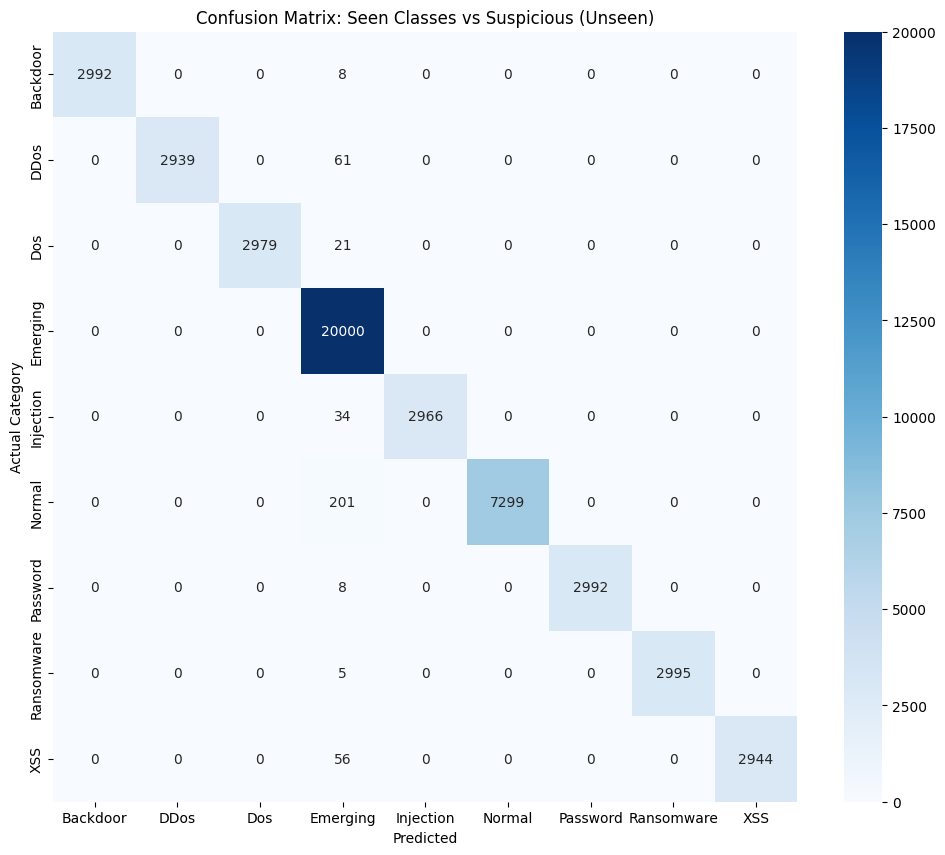


--- Detailed Analysis of Unseen Attack Detection ---


In [17]:
def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []

    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1).cpu().numpy()

            best_class_idx, region, nn_conf = gate.predict_region(probs)

            for k_idx, r in zip(best_class_idx, region):
                if r == "inside":
                    preds.append(le.inverse_transform([k_idx])[0])  # known class
                else:
                    preds.append("Emerging")  # boundary suspicious

    return np.array(preds)


# 1) Extract probability-vectors from TRAIN data (known classes only)
train_feats, train_labels = get_prob_features(model, train_loader, device, temperature=1.0)

# 2) Fit the Min–Max 3-way gate
gate = MinMaxThreeWayGate(q=9).fit(train_feats, train_labels)

print("Gate fitted. Train feats:", train_feats.shape, "Train labels:", train_labels.shape)

print("\nRunning Min–Max 3-way Inference on Mixed Test Set...")
y_pred = predict_minmax_3labels(model, test_loader, gate, le, device)
unique, counts = np.unique(y_pred, return_counts=True)
print(dict(zip(unique, counts)))

#%% [markdown]
# ## 8. Evaluation

y_true_mapped = []
for label in y_test_final_str:
    if label in UNSEEN_CLASSES:
        y_true_mapped.append('Emerging')
    else:
        y_true_mapped.append(label)

print("\nClassification Report:")
print(classification_report(y_true_mapped, y_pred))

# Confusion Matrix
plt.figure(figsize=(12, 10))
labels = sorted(list(set(y_true_mapped) | set(y_pred)))
cm = confusion_matrix(y_true_mapped, y_pred, labels=labels)

report_dict=report_dict = classification_report(
    y_true_mapped,
    y_pred,
    output_dict=True,
    zero_division=0
)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Seen Classes vs Suspicious (Unseen)")
plt.ylabel('Actual Category')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix_ton_iot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Detailed Analysis of Unseen Attack Detection ---")
analysis_df = pd.DataFrame({
    'Actual_Category': y_test_final_str,
    'Prediction': y_pred
})


Running Inference on Mixed Test Set...

PART A: SEEN (KNOWN) ATTACKS


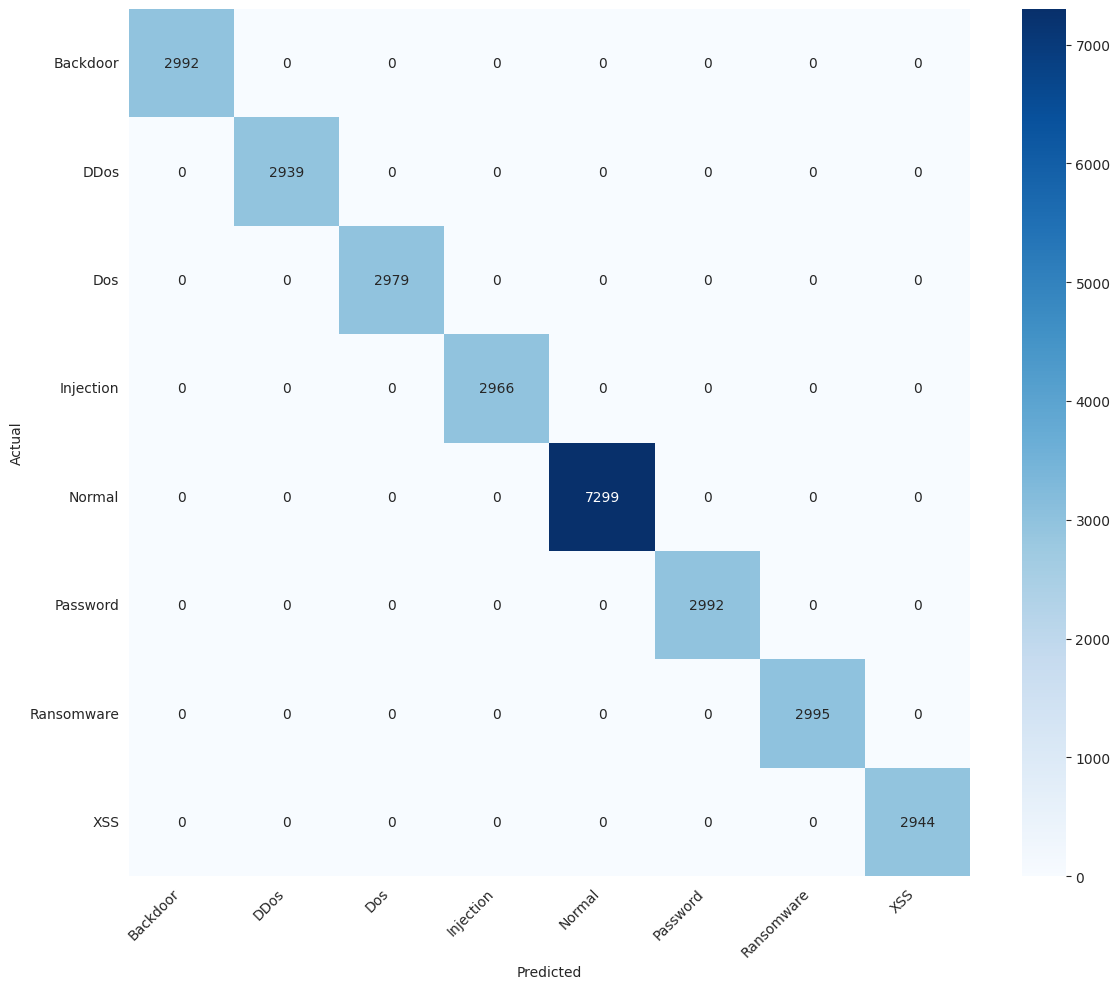

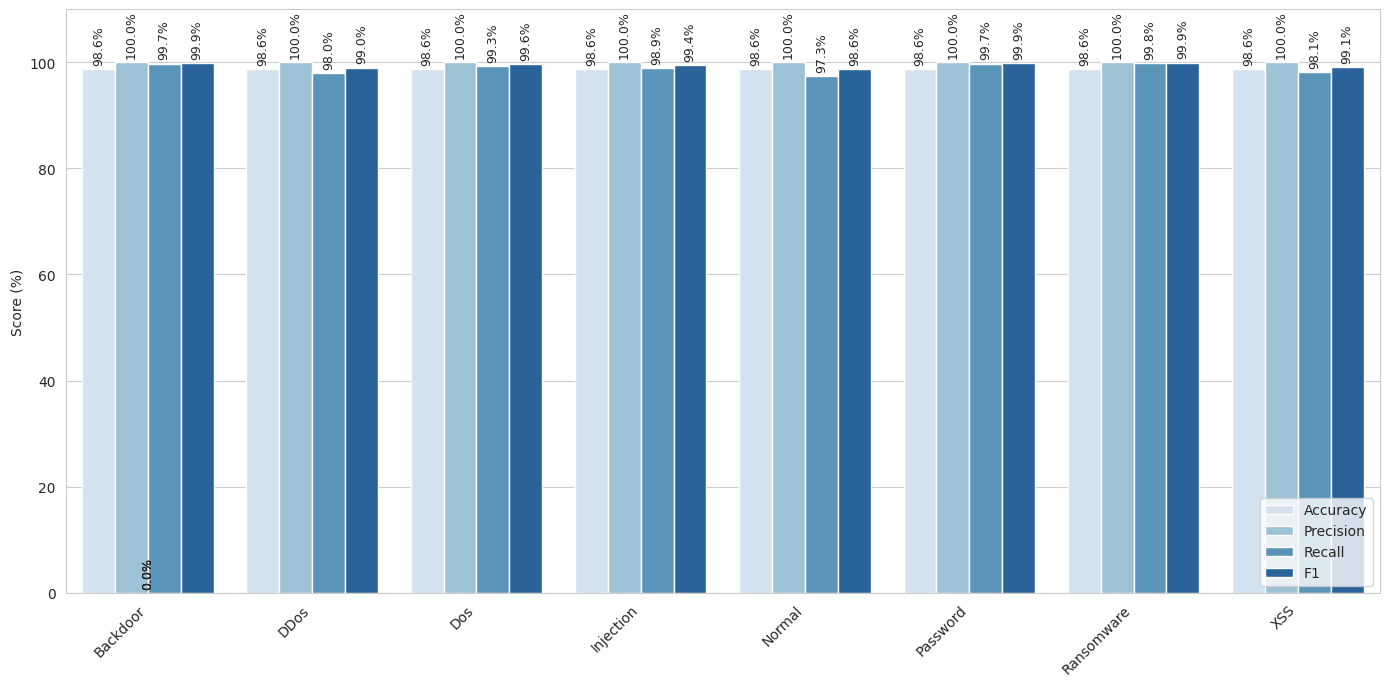


PART B: UNSEEN (UNKNOWN) ATTACKS


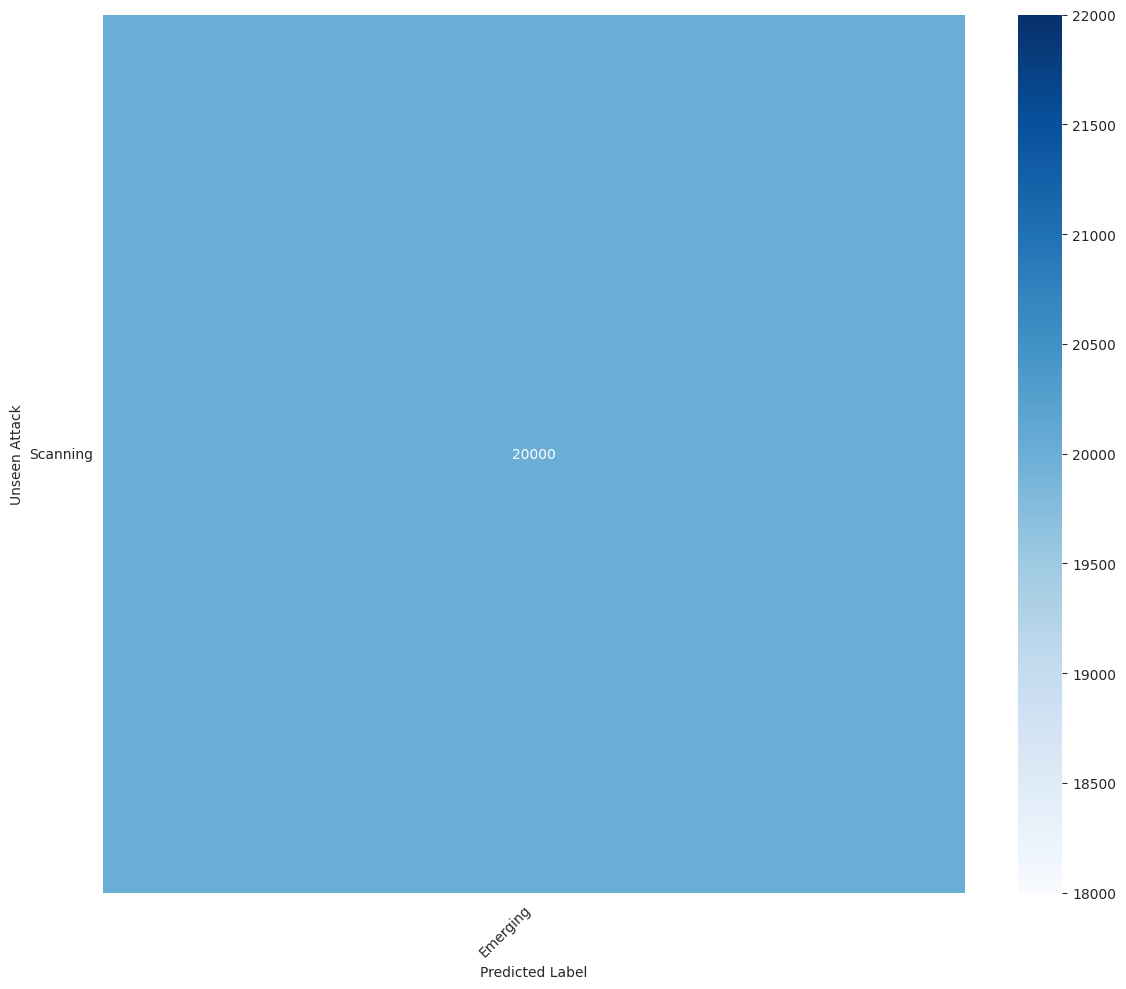

KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['Emerging Rate (%)']"

In [18]:
from sklearn.metrics import classification_report, accuracy_score

print("\nRunning Inference on Mixed Test Set...")
# NOTE: use the correct predictor you are using in your notebook
y_pred = predict_minmax_3labels(model, test_loader, gate, le, device)

# Ensure numpy arrays
y_true_all = np.asarray(y_test_final_str)
y_pred_all = np.asarray(y_pred)

# Safety: align lengths
n = min(len(y_true_all), len(y_pred_all))
if len(y_true_all) != len(y_pred_all):
    print(f"[WARN] Length mismatch y_true={len(y_true_all)} vs y_pred={len(y_pred_all)}. Truncating to n={n}.")
y_true_all = y_true_all[:n]
y_pred_all = y_pred_all[:n]

known_classes = set(le.classes_)
is_seen_mask = np.array([lbl in known_classes for lbl in y_true_all])

y_true_seen = y_true_all[is_seen_mask]
y_pred_seen = y_pred_all[is_seen_mask]

y_true_unseen = y_true_all[~is_seen_mask]
y_pred_unseen = y_pred_all[~is_seen_mask]

# Style
BLUE_CMAP = "Blues"
sns.set_style("whitegrid")


# ============================
# PART A: SEEN ATTACKS
#   - Confusion Matrix (NO Emerging)
#   - ONE CHART: Accuracy / Precision / Recall / F1 bars per class
# ============================
print("\n" + "="*55)
print("PART A: SEEN (KNOWN) ATTACKS")
print("="*55)

if len(y_true_seen) == 0:
    print("No Seen samples in this test set.")
else:
    # Confusion Matrix for seen attacks (remove Emerging/Unknown columns if present)
    df_cm_seen = pd.crosstab(
        pd.Series(y_true_seen, name="Actual"),
        pd.Series(y_pred_seen, name="Predicted")
    )
    for bad in ["Emerging", "Unknown"]:
        if bad in df_cm_seen.columns:
            df_cm_seen = df_cm_seen.drop(columns=[bad])
        if bad in df_cm_seen.index:
            df_cm_seen = df_cm_seen.drop(index=[bad])

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_seen, annot=True, fmt="d", cmap=BLUE_CMAP)
    plt.title("")  # blank
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("confusion_seen_attacks_blues.png", dpi=300)
    plt.show()

    # ---- Metrics per class ----
    seen_report = classification_report(
        y_true_seen,
        y_pred_seen,
        output_dict=True,
        zero_division=0
    )

    # Only actual seen classes (exclude meta keys + Emerging/Unknown if present)
    seen_classes = [
        k for k in seen_report.keys()
        if k not in ["accuracy", "macro avg", "weighted avg", "Emerging", "Unknown"]
    ]

    # Global accuracy over seen set (same value repeated per class for plotting)
    acc_seen = accuracy_score(y_true_seen, y_pred_seen) * 100.0

    metrics_df = pd.DataFrame({
        "Class": seen_classes,
        "Accuracy": [acc_seen] * len(seen_classes),
        "Precision": [seen_report[c]["precision"] * 100 for c in seen_classes],
        "Recall":    [seen_report[c]["recall"] * 100 for c in seen_classes],
        "F1":        [seen_report[c]["f1-score"] * 100 for c in seen_classes],
    })

    # Long format for grouped bars
    metrics_long = metrics_df.melt(
        id_vars="Class",
        value_vars=["Accuracy", "Precision", "Recall", "F1"],
        var_name="Metric",
        value_name="Score (%)"
    )

    plt.figure(figsize=(14, 7))
    ax = sns.barplot(
        data=metrics_long,
        x="Class",
        y="Score (%)",
        hue="Metric",
        palette=sns.color_palette(BLUE_CMAP, n_colors=4)
    )
    plt.title("")  # blank
    plt.ylabel("Score (%)")
    plt.xlabel("")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 110)

    # Value labels on bars
    for p in ax.patches:
        val = p.get_height()
        ax.annotate(
            f"{val:.1f}%",
            (p.get_x() + p.get_width() / 2, val),
            ha="center", va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
            rotation=90
        )

    plt.legend(title="")
    plt.tight_layout()
    plt.savefig("bars_seen_metrics_accuracy_precision_recall_f1_blues.png", dpi=300)
    plt.show()


# ============================
# PART B: UNSEEN ATTACKS
#   - Confusion Matrix (Actual unseen types vs predicted labels)
#   - ONE CHART: Detection-as-Emerging (Recall) + False Known + Unknown rate
# ============================
print("\n" + "="*55)
print("PART B: UNSEEN (UNKNOWN) ATTACKS")
print("="*55)

if len(y_true_unseen) == 0:
    print("No Unseen samples in this test set.")
else:
    # Confusion Matrix for unseen attacks
    df_cm_unseen = pd.crosstab(
        pd.Series(y_true_unseen, name="Unseen Attack"),
        pd.Series(y_pred_unseen, name="Predicted Label")
    )

    # Put Emerging first if present (optional)
    cols = list(df_cm_unseen.columns)
    if "Emerging" in cols:
        cols.remove("Emerging")
        cols.insert(0, "Emerging")
        df_cm_unseen = df_cm_unseen[cols]

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_unseen, annot=True, fmt="d", cmap=BLUE_CMAP)
    plt.title("")  # blank
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("confusion_unseen_attacks_blues.png", dpi=300)
    plt.show()

    # Per-unseen-type rates:
    # - Emerging rate (detection)
    # - Unknown rate
    # - Misclassified-as-known rate
    unseen_df = pd.DataFrame({"Actual": y_true_unseen, "Predicted": y_pred_unseen})

    def _rates(group):
        total = len(group)
        emerging = (group == "Emerging").sum()
        unknown = (group == "Unknown").sum()
        known_mis = total - emerging - unknown
        return pd.Series({
            "Emerging Rate (%)": emerging / total * 100,
            "Unknown Rate (%)": unknown / total * 100,
            "Misclassified as Known (%)": known_mis / total * 100
        })

    unseen_rates = unseen_df.groupby("Actual")["Predicted"].apply(_rates).reset_index().rename(columns={"Actual": "Unseen Attack Type"})

    unseen_long = unseen_rates.melt(
        id_vars="Unseen Attack Type",
        value_vars=["Emerging Rate (%)"],
        var_name="Metric",
        value_name="Rate (%)"
    )

    plt.figure(figsize=(14, 7))
    ax2 = sns.barplot(
        data=unseen_long,
        x="Unseen Attack Type",
        y="Rate (%)",
        hue="Metric",
        palette=sns.color_palette(BLUE_CMAP, n_colors=3)
    )
    plt.title("")  # blank
    plt.ylabel("Rate (%)")
    plt.xlabel("")

    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 110)

    for p in ax2.patches:
        val = p.get_height()
        ax2.annotate(
            f"{val:.1f}%",
            (p.get_x() + p.get_width() / 2, val),
            ha="center", va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points"
        )

    plt.legend(title="")
    plt.tight_layout()
    plt.savefig("bars_unseen_rates_emerging_unknown_known_blues.png", dpi=300)
    plt.show()

print("\nCharts saved:")
print("1) confusion_seen_attacks_blues.png")
print("2) bars_seen_metrics_accuracy_precision_recall_f1_blues.png")
print("3) confusion_unseen_attacks_blues.png")
print("4) bars_unseen_rates_emerging_unknown_known_blues.png")

/tmp/ipykernel_55/49483150.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax_overall = sns.barplot(


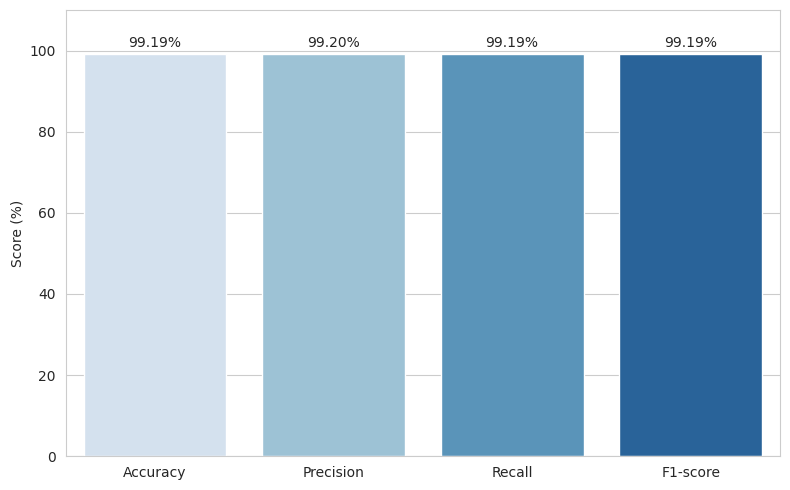

In [19]:
cmap_name = "Blues"
# ==========================================
# 4) Overall Metrics Visualization (Accuracy, Precision, Recall, F1)
# ==========================================

# Get overall metrics (use weighted avg for multi-class)
acc = report_dict["accuracy"] * 100
prec = report_dict["weighted avg"]["precision"] * 100
rec = report_dict["weighted avg"]["recall"] * 100
f1 = report_dict["weighted avg"]["f1-score"] * 100

overall_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [acc, prec, rec, f1]
})

plt.figure(figsize=(8, 5))
ax_overall = sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score (%)",
    palette=sns.color_palette(cmap_name, n_colors=len(overall_df))
)

plt.title("")
plt.ylabel("Score (%)")
plt.xlabel("")
plt.ylim(0, 110)

# Add values on top of bars
for container in ax_overall.containers:
    ax_overall.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("overall_seen_metrics.png", dpi=300)
plt.show()


In [27]:
data = pd.read_csv("/kaggle/input/ton-iot-network-dataset/train_test_network.csv")

In [28]:
data["label"].value_counts()

label
1    161043
0     50000
Name: count, dtype: int64

In [29]:
len(data.columns)

44

In [30]:
data['type'].value_counts()

type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
scanning      20000
ransomware    20000
xss           20000
mitm           1043
Name: count, dtype: int64

In [31]:
plt.savefig("Confusion_matrix.png")

<Figure size 640x480 with 0 Axes>

In [32]:
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import confusion_matrix, classification_report, f1_score, roc_curve, auc, accuracy_score, precision_recall_fscore_support
from itertools import cycle
print("\n--- Generating ROC Curves ---")
# Filter test set to only include SEEN classes for valid ROC calculation
mask_seen = np.isin(y_test_final_str, SEEN_CLASSES)
y_test_seen_only = y_test_final_str[mask_seen]
X_test_seen_only = X_test_final[mask_seen] 

# Create a temporary loader
seen_ds = IoTDataset(X_test_seen_only, np.zeros(len(X_test_seen_only))) 
seen_loader = DataLoader(seen_ds, batch_size=CONFIG['batch_size'], shuffle=False)

# Get raw probabilities
probs_seen, _ = get_probabilities(model, seen_loader) 

# Binarize labels
classes = list(le.classes_)
y_test_bin = label_binarize(y_test_seen_only, classes=classes)
n_classes = y_test_bin.shape[1]

# Plot
plt.figure(figsize=(10, 8))
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), probs_seen.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-average (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot each class
colors = cycle(sns.color_palette("husl", n_classes)) # Distinct colors for lines
for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs_seen[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multiclass ROC Curve (Seen Classes)', fontsize=16)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/multiclass_roc_curve.png', dpi=300)
plt.show()

print("\nAll charts generated and saved.")


--- Generating ROC Curves ---


NameError: name 'get_probabilities' is not defined

In [19]:
columns=list(pd.read_csv("/kaggle/input/ton-iot-network-dataset/train_test_network.csv").columns)

Num features: 39 | Num classes: 8

Predicted class: Normal | prob: 0.9259105324745178
Probabilities: {'Backdoor': 0.010212838649749756, 'DDos': 0.010867378674447536, 'Dos': 0.010897948406636715, 'Injection': 0.011328178457915783, 'Normal': 0.9259105324745178, 'Password': 0.01049746572971344, 'Ransomware': 0.010446113534271717, 'XSS': 0.009839520789682865}

Building SHAP background (kmeans=60)...
Creating SHAP KernelExplainer on LOGITS...
Computing SHAP values for one sample...


  0%|          | 0/1 [00:00<?, ?it/s]

x features: 39 | shap vals: 39 | feature_names: 39


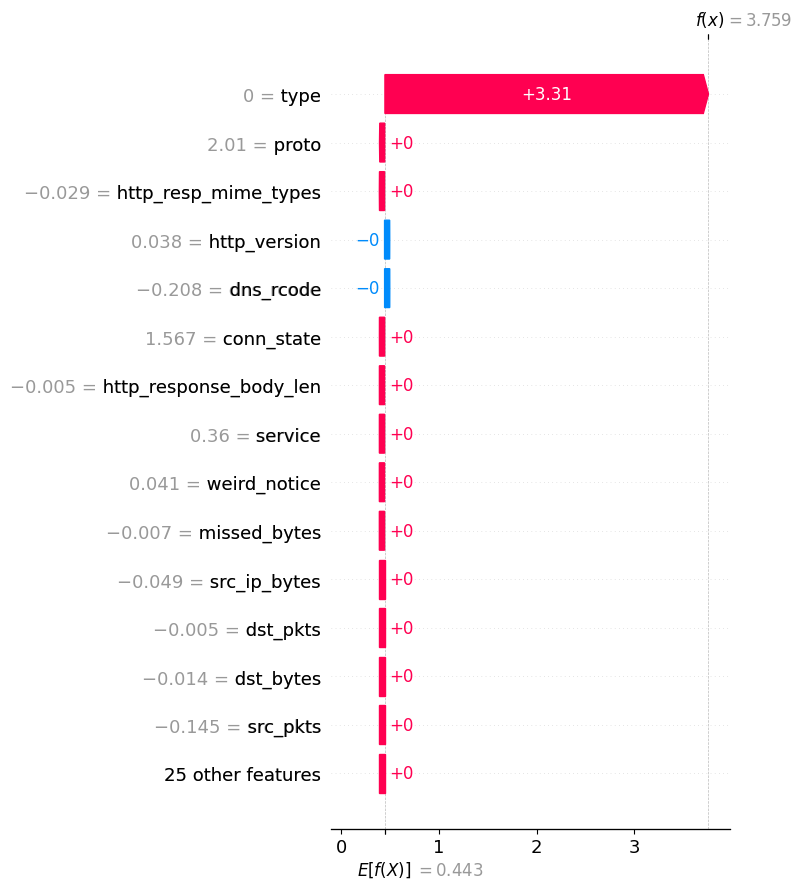


Generating LIME explanation...


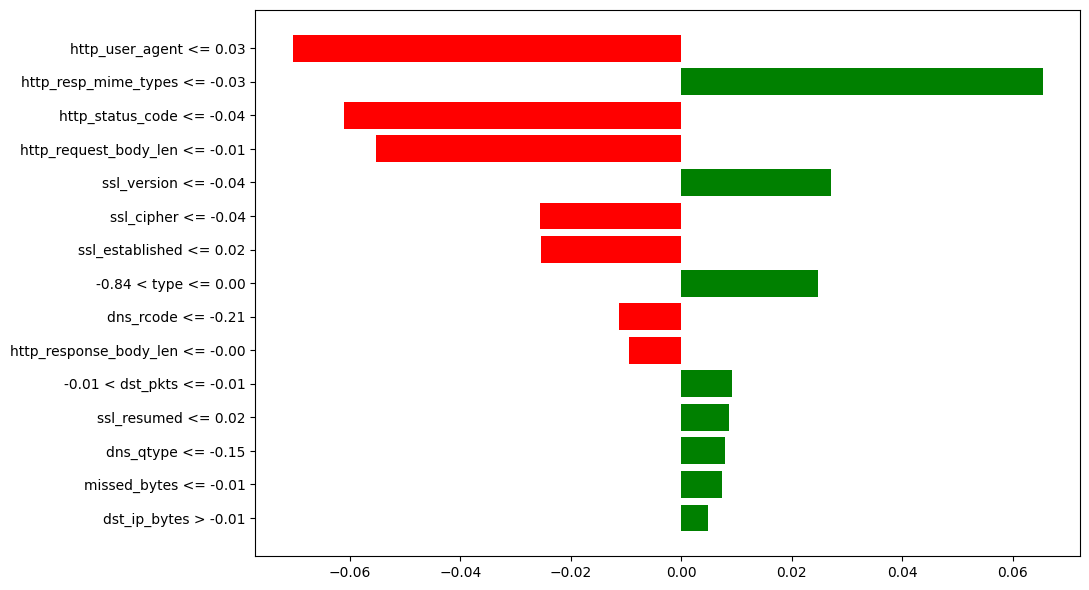


Top LIME features (feature -> weight):
http_user_agent <= 0.03                       -0.0703
http_resp_mime_types <= -0.03                 +0.0654
http_status_code <= -0.04                     -0.0611
http_request_body_len <= -0.01                -0.0553
ssl_version <= -0.04                          +0.0270
ssl_cipher <= -0.04                           -0.0256
ssl_established <= 0.02                       -0.0255
-0.84 < type <= 0.00                          +0.0247
dns_rcode <= -0.21                            -0.0112
http_response_body_len <= -0.00               -0.0095
-0.01 < dst_pkts <= -0.01                     +0.0092
ssl_resumed <= 0.02                           +0.0086
dns_qtype <= -0.15                            +0.0079
missed_bytes <= -0.01                         +0.0074
dst_ip_bytes > -0.01                          +0.0048


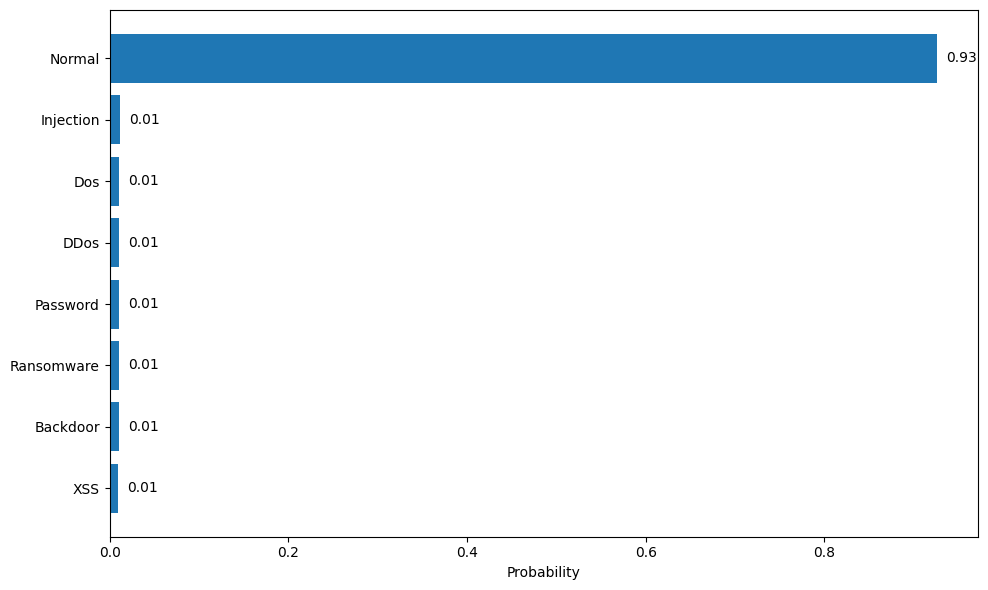

In [25]:
# ============================================================
# XAI FOR ToN-IoT (44 features): SHAP Waterfall + LIME Chart
# ============================================================

import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# -----------------------------
# 1) Build feature names (IMPORTANT)
# Use the exact columns used for training (after drops + encoding)
# -----------------------------
# In your load_and_process(), X_raw is created before scaler:
# X_raw = df.drop(columns=[...])
# So we reconstruct the same list here:
# NOTE: if you still have `X_raw` in memory, use: feature_names_real = list(X_raw.columns)

def get_feature_names_from_dataset(config):
    df = pd.read_csv(config["dataset_path"])
    df.replace('-', np.nan, inplace=True)
    df['category'] = df['type'].map(ATTACK_MAPPING)
    df.dropna(subset=['category'], inplace=True)
    df = df[df['category'] != 'Mitm']

    drop_cols = ['src_ip', 'dst_ip', 'label', 'category','weird_addl','weird_name']
    X_raw = df.drop(columns=[c for c in drop_cols if c in df.columns], axis=1)

    return list(X_raw.columns)

feature_names_real = get_feature_names_from_dataset(CONFIG)
class_names = le.classes_

print("Num features:", len(feature_names_real), "| Num classes:", len(class_names))


# -----------------------------
# 2) Prepare 2D arrays for XAI tools
# -----------------------------
X_train_2d = X_train.reshape(X_train.shape[0], -1).astype(np.float32)      # (N,44)
X_test_2d  = X_test_final.reshape(X_test_final.shape[0], -1).astype(np.float32)

assert X_train_2d.shape[1] == len(feature_names_real), "Feature name mismatch with X_train_2d!"
assert X_test_2d.shape[1] == len(feature_names_real), "Feature name mismatch with X_test_2d!"


# -----------------------------
# 3) Prediction wrappers
#    - SHAP: explain LOGITS (best waterfall visibility)
#    - LIME: uses probabilities
# -----------------------------
device_xai = device

def predict_logits_np(data_2d):
    """(N,F) -> (N,C) logits"""
    if isinstance(data_2d, pd.DataFrame):
        data_2d = data_2d.values.astype(np.float32)
    else:
        data_2d = np.asarray(data_2d, dtype=np.float32)

    data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)  # (N,44,1)
    x = torch.tensor(data_3d, dtype=torch.float32, device=device_xai)

    model.eval()
    with torch.no_grad():
        logits = model(x)  # (N,C)

    return logits.detach().cpu().numpy()

def predict_proba_np(data_2d):
    """(N,F) -> (N,C) probs (stable softmax)"""
    logits = predict_logits_np(data_2d)
    logits = logits - logits.max(axis=1, keepdims=True)
    exps = np.exp(logits)
    return exps / exps.sum(axis=1, keepdims=True)


# -----------------------------
# 4) Helpers for SHAP multiclass output
# -----------------------------
def get_shap_vector_for_class(shap_out, class_idx, sample_row=0):
    """
    Handles:
      - list: shap_out[class] -> (n,f)
      - array: (n,f,c)
      - array: (n,f)
    Returns (f,)
    """
    if isinstance(shap_out, list):
        return np.asarray(shap_out[class_idx])[sample_row, :]
    arr = np.asarray(shap_out)
    if arr.ndim == 2:
        return arr[sample_row, :]
    if arr.ndim == 3:
        return arr[sample_row, :, class_idx]
    raise ValueError(f"Unsupported SHAP output shape: {arr.shape}")

def get_expected_value_for_class(expected_value, class_idx):
    if isinstance(expected_value, (list, np.ndarray)):
        return expected_value[class_idx]
    return expected_value


# ============================================================
# 5) SHAP WATERFALL (single sample)
# ============================================================
sample_idx = 2  # <-- change sample here

x1 = X_test_2d[sample_idx].reshape(1, -1)
probs = predict_proba_np(x1)[0]
pred_class_idx = int(np.argmax(probs))

print("\nPredicted class:", class_names[pred_class_idx], "| prob:", float(probs[pred_class_idx]))
print("Probabilities:", {str(class_names[i]): float(probs[i]) for i in range(len(class_names))})

# Build background (fast)
print("\nBuilding SHAP background (kmeans=60)...")
background = shap.kmeans(X_train_2d, 80)

print("Creating SHAP KernelExplainer on LOGITS...")
explainer = shap.KernelExplainer(predict_logits_np, background)

print("Computing SHAP values for one sample...")
shap_out = explainer.shap_values(x1, nsamples=800)  # increase to 1500 for smoother (slower)

vals = get_shap_vector_for_class(shap_out, pred_class_idx, sample_row=0)
base_val = get_expected_value_for_class(explainer.expected_value, pred_class_idx)

print("x features:", x1.shape[1], "| shap vals:", vals.shape[0], "| feature_names:", len(feature_names_real))

# Build Explanation
exp = shap.Explanation(
    values=vals,
    base_values=base_val,
    data=x1[0],
    feature_names=feature_names_real
)

plt.figure(figsize=(11, 7))
shap.plots.waterfall(exp, max_display=15, show=False)
plt.title(f"", fontsize=14)
plt.tight_layout()
plt.savefig(f"shap_waterfall_sample{sample_idx}_{class_names[pred_class_idx]}.png",
            dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 6) LIME LOCAL EXPLANATION (real LIME chart)
# ============================================================
print("\nGenerating LIME explanation...")

lime_explainer = LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names_real,
    class_names=[str(c) for c in class_names],
    mode="classification",
    discretize_continuous=True
)

lime_exp = lime_explainer.explain_instance(
    data_row=X_test_2d[sample_idx],
    predict_fn=predict_proba_np,
    num_features=15,
    top_labels=1
)

# Plot for predicted label
fig = lime_exp.as_pyplot_figure(label=pred_class_idx)
fig.set_size_inches(11, 6)
plt.title(f"", fontsize=14)
plt.tight_layout()
plt.savefig(f"lime_explanation_sample{sample_idx}_{class_names[pred_class_idx]}.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("\nTop LIME features (feature -> weight):")
for feat, w in lime_exp.as_list(label=pred_class_idx):
    print(f"{feat:45s} {w:+.4f}")


# ============================================================
# (Optional) Probability Bar Chart (NOT LIME, just confidence)
# ============================================================
plt.figure(figsize=(10, 6))
order = np.argsort(probs)[::-1]
plt.barh([class_names[i] for i in order], probs[order])
plt.gca().invert_yaxis()
plt.xlabel("Probability")
plt.title(f"")
for y_i, i in enumerate(order):
    plt.text(float(probs[i]) + 0.01, y_i, f"{probs[i]:.2f}", va="center")
plt.tight_layout()
plt.savefig(f"probabilities_sample{sample_idx}.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
# ============================================================
# UPDATED (PAPER-READY) LIME (HTML->PNG) + SHAP SUMMARY (PNG)
# - GPU inference for model predictions
# - LIME: save HTML + convert HTML->PNG + save pyplot PNG
# - SHAP: summary beeswarm + bar saved as PNG (high DPI)
# ============================================================

import os, time, glob
import numpy as np
import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular
import torch
from selenium import webdriver
from selenium.webdriver.chrome.options import Options

# -------------------------
# REQUIREMENTS (Kaggle)
# -------------------------
# Run once if selenium/chrome not installed:
# !apt-get update -y
# !apt-get install -y chromium-browser chromium-chromedriver
# !pip -q install selenium

# -------------------------
# SAFETY CHECKS
# -------------------------
if "X_train" not in globals() or "X_test_final" not in globals():
    raise NameError("X_train and X_test_final are not defined. Run your dataset pipeline first.")

if "SEEN_CLASSES" not in globals() or SEEN_CLASSES is None:
    raise NameError("SEEN_CLASSES is not defined. It must match your model output class order.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------
# FEATURE NAMES (robust)
# -------------------------
if "columns" in globals() and columns is not None:
    FEATURE_NAMES = list(columns)
elif "feature_names_real" in globals() and feature_names_real is not None:
    FEATURE_NAMES = list(feature_names_real)
else:
    # fallback
    FEATURE_NAMES = [f"Feature_{i}" for i in range(X_train.shape[1])]

# -------------------------
# 3D -> 2D (N,F)
# -------------------------
X_train_3d = X_train
X_test_3d  = X_test_final

X_train_2d = X_train_3d.reshape(X_train_3d.shape[0], X_train_3d.shape[1]).astype(np.float32)
X_test_2d  = X_test_3d.reshape(X_test_3d.shape[0],  X_test_3d.shape[1]).astype(np.float32)

# force consistent feature count
F = min(X_train_2d.shape[1], X_test_2d.shape[1], len(FEATURE_NAMES))
X_train_2d = X_train_2d[:, :F]
X_test_2d  = X_test_2d[:, :F]
FEATURE_NAMES = FEATURE_NAMES[:F]

print(f"Using F={F} features. Train={X_train_2d.shape}, Test={X_test_2d.shape}")

# -------------------------
# GPU PREDICT FUNCTION
# -------------------------
def predict_proba_gpu(data_2d: np.ndarray) -> np.ndarray:
    data_2d = np.asarray(data_2d, dtype=np.float32)
    data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)  # (N,F,1)
    x = torch.from_numpy(data_3d).to(device)
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
    return probs

# -------------------------
# Ensure class names length matches model output
# -------------------------
num_classes_model = predict_proba_gpu(X_train_2d[:2]).shape[1]
if len(SEEN_CLASSES) != num_classes_model:
    print(f"[WARN] SEEN_CLASSES={len(SEEN_CLASSES)} but model outputs={num_classes_model}. Fixing names.")
    SEEN_CLASSES = list(SEEN_CLASSES)[:num_classes_model]
    if len(SEEN_CLASSES) < num_classes_model:
        SEEN_CLASSES += [f"Class_{i}" for i in range(len(SEEN_CLASSES), num_classes_model)]

print("Using classes:", SEEN_CLASSES)

# -------------------------
# Background + explain subset
# -------------------------
background_size = 500
explain_size = 1000

background_data_np = shap.sample(X_train_2d, background_size, random_state=42)
X_explain = X_test_2d[:explain_size]

# predictions for representative samples per class
probs_explain = predict_proba_gpu(X_explain)
preds_explain = np.argmax(probs_explain, axis=1)

# ============================================================
# HTML -> PNG (Headless Chrome)
# ============================================================
def html_to_png(html_path, png_path, width=1700, height=1100, wait=2.0):
    chrome_options = Options()
    chrome_options.add_argument("--headless=new")
    chrome_options.add_argument("--no-sandbox")
    chrome_options.add_argument("--disable-dev-shm-usage")
    chrome_options.add_argument(f"--window-size={width},{height}")

    driver = webdriver.Chrome(options=chrome_options)
    driver.get("file://" + os.path.abspath(html_path))
    time.sleep(wait)
    driver.save_screenshot(png_path)
    driver.quit()
    print(f"Saved PNG: {png_path}")

# ============================================================
# 1) LIME (per class): HTML + HTML->PNG + pyplot PNG + probs PNG
# ============================================================
print("\n--- LIME: Initializing Explainer ---")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=background_data_np,
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    mode="classification",
    discretize_continuous=True
)

print("\n--- LIME: Generating per-class explanations ---")
for class_idx, class_name in enumerate(SEEN_CLASSES):
    idxs = np.where(preds_explain == class_idx)[0]
    if len(idxs) == 0:
        print(f"Skip {class_name}: no predicted samples in subset.")
        continue

    sample_idx = int(idxs[0])
    x_row = X_explain[sample_idx]

    exp = lime_explainer.explain_instance(
        data_row=x_row,
        predict_fn=predict_proba_gpu,
        num_features=10,
        top_labels=1
    )

    # --- (A) Save HTML ---
    html_file = f"lime_explanation_{class_name}.html"
    exp.save_to_file(html_file)

    # --- (B) Convert HTML -> PNG ---
    html_png = f"lime_explanation_{class_name}.png"
    html_to_png(html_file, html_png, width=1800, height=1200, wait=2.0)

    # --- (C) Feature contribution plot (matplotlib) ---
    fig = exp.as_pyplot_figure(label=class_idx)
    plt.title(f"LIME Feature Contributions: {class_name}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"lime_feature_plot_{class_name}.png", dpi=600, bbox_inches="tight")
    plt.close()

    # --- (D) Probability plot ---
    sample_probs = probs_explain[sample_idx]
    fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
    y_pos = np.arange(len(SEEN_CLASSES))
    ax.barh(y_pos, sample_probs)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(SEEN_CLASSES)
    ax.set_xlabel("Probability")
    ax.set_title(f"Prediction Probabilities: {class_name} (sample {sample_idx})", fontsize=12)
    ax.set_xlim(0, 1.05)

    for i, v in enumerate(sample_probs):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center")

    plt.savefig(f"lime_probability_plot_{class_name}.png", dpi=600, bbox_inches="tight")
    plt.close()

print("\n✅ LIME done. (HTML + HTML->PNG + plots saved)")

# ============================================================
# 2) SHAP (KernelExplainer): summary beeswarm + summary bar
# ============================================================
print("\n--- SHAP: KernelExplainer (this can be slow) ---")
explainer = shap.KernelExplainer(predict_proba_gpu, background_data_np)

nsamples = 50
shap_values = explainer.shap_values(X_explain, nsamples=nsamples)

# ---- SHAP Summary (Beeswarm) ----
print("Saving SHAP summary beeswarm...")
plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    show=False
)
plt.title("SHAP Summary Plot (Beeswarm)", fontsize=14)
plt.savefig("shap_summary_beeswarm.png", dpi=600, bbox_inches="tight")
plt.close()

# ---- SHAP Summary (Bar) ----
print("Saving SHAP summary bar...")
plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    plot_type="bar",
    show=False
)
plt.title("Mean |SHAP| (Global Importance)", fontsize=14)
plt.savefig("shap_summary_bar.png", dpi=600, bbox_inches="tight")
plt.close()

print("\n✅ SHAP summary charts saved:")
print(" - shap_summary_beeswarm.png")
print(" - shap_summary_bar.png")


Using F=39 features. Train=(133000, 39), Test=(48500, 39)
Using classes: ['Normal', 'Ransomware', 'Backdoor', 'Injection', 'DDos', 'Password', 'Dos', 'XSS']

--- LIME: Initializing Explainer ---

--- LIME: Generating per-class explanations ---
Saved PNG: lime_explanation_Normal.png
Saved PNG: lime_explanation_Ransomware.png
Saved PNG: lime_explanation_Backdoor.png
Saved PNG: lime_explanation_Injection.png
Saved PNG: lime_explanation_DDos.png
Saved PNG: lime_explanation_Password.png
Saved PNG: lime_explanation_Dos.png
Saved PNG: lime_explanation_XSS.png


Using 500 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.



✅ LIME done. (HTML + HTML->PNG + plots saved)

--- SHAP: KernelExplainer (this can be slow) ---


  0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=1.223e-06, with an active set of 6 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=9.121e-06, with an active set of 5 regressors, and the smallest cholesky pivot element being 4.215e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 4 iterations, i.e. alpha=4.675e-06, with an active set of 4 regressors, and the smallest cholesky pivot element being 4

...

/tmp/ipykernel_55/1490069025.py:194: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy gl

Saving SHAP summary bar...


/tmp/ipykernel_55/1490069025.py:208: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(



✅ SHAP summary charts saved:
 - shap_summary_beeswarm.png
 - shap_summary_bar.png


<Figure size 1200x700 with 0 Axes>

In [26]:
def predict_proba_wrapper(data_2d):
    model.eval()
    model.to(device)  # <--- ensure model on same device

    data_2d = np.asarray(data_2d, dtype=np.float32)
    data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)

    x = torch.tensor(data_3d, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
    return probs


In [27]:
# Model class names from label encoder
class_names_model = list(le.classes_)

print("Model classes:", class_names_model)


Model classes: ['Backdoor', 'DDos', 'Dos', 'Injection', 'Normal', 'Password', 'Ransomware', 'XSS']


Feature count: 39


  0%|          | 0/1 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-0.248994' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-72.2235582984' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incom

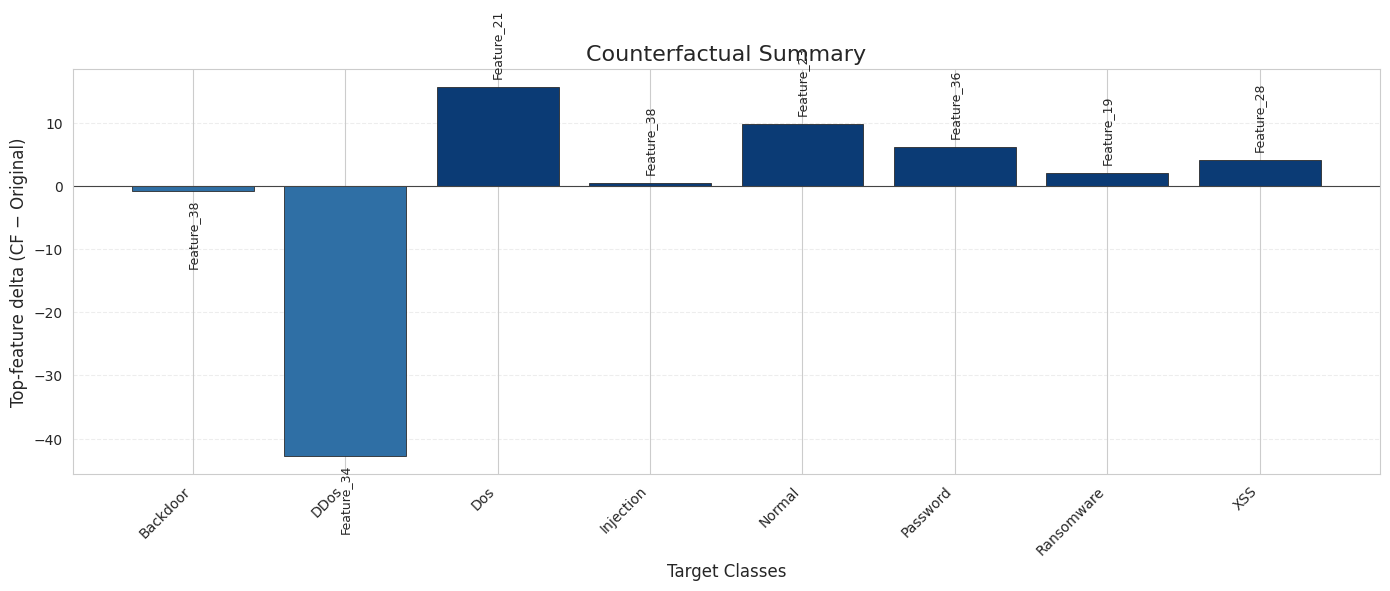

Saved: counterfactual_summary_onegraph.png


  0%|          | 0/1 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2.68721681' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '42.337218095' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incomp

Saved: counterfactual_features_Backdoor.png


  0%|          | 0/1 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-1.193222' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-12.938149494' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incomp

Saved: counterfactual_features_DDos.png


...

Saved: counterfactual_features_Password.png


  0%|          | 0/1 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.784152372' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-28.345056617' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of inco

Saved: counterfactual_features_Ransomware.png


  0%|          | 0/1 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1.2657227' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '18.095749453' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  candidate_cfs.at[k, selected_features[k][0]] = random_instances.at[k, selected_features[k][0]]
/usr/local/lib/python3.12/dist-packages/dice_ml/explainer_interfaces/dice_random.py:116: FutureWarning: Setting an item of incompa

Saved: counterfactual_features_XSS.png


In [28]:
import dice_ml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# CONFIG
# =========================
idx_to_explain = 0
total_CFs = 3          # generate a few, we take the best 1
epsilon = 1e-4
top_k_features = 10     # for per-class charts
dpi = 600

# =========================
# Sklearn-like wrapper for DiCE
# =========================
class SklearnModelWrapper:
    def __init__(self, prediction_function):
        self.prediction_function = prediction_function

    def predict_proba(self, instances):
        return self.prediction_function(instances)

    def predict(self, instances):
        probs = self.prediction_function(instances)
        return np.argmax(probs, axis=1)

model_dice = SklearnModelWrapper(predict_proba_wrapper)

# =========================
# Prepare DiCE Data + Model
# =========================

# ------------------------------------------------
# SAFE FEATURE NAME INITIALIZATION
# ------------------------------------------------
if "feature_names_real" not in globals():
    if "X_raw" in globals():
        feature_names_real = list(X_raw.columns)
    else:
        feature_names_real = [f"Feature_{i}" for i in range(X_train_2d.shape[1])]

# ensure alignment
feature_names_real = feature_names_real[:X_train_2d.shape[1]]

print("Feature count:", len(feature_names_real))

df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names_real)
df_train_dice["label"] = y_train

d = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names_real,
    outcome_name="label"
)

m = dice_ml.Model(model=model_dice, backend="sklearn")
exp_dice = dice_ml.Dice(d, m, method="random")   # keep "random" like you used

# =========================
# Query sample
# =========================
query_instance = pd.DataFrame([X_test_2d[idx_to_explain]], columns=feature_names_real)
original_vals = query_instance.iloc[0].values.astype(float)

# helper: best CF among generated ones (min L1 distance)
def select_best_cf(cf_df, feature_names, original_vals):
    if cf_df is None or cf_df.empty:
        return None
    cands = cf_df[feature_names].values.astype(float)
    dists = np.sum(np.abs(cands - original_vals), axis=1)
    return cf_df.iloc[int(np.argmin(dists))]

# helper: nice blue theme (positive dark, negative medium, no-change light)
def bar_color(delta):
    if np.isnan(delta):
        return "#bdbdbd"  # grey for error/none
    if abs(delta) < epsilon:
        return "#d9e6f2"  # very light blue
    return "#0b3b75" if delta > 0 else "#2f6fa5"  # dark/medium blues

# ============================================================
# A) ONE CHART (like your screenshot): 1 bar per target class
# ============================================================
results_summary = []

for target_idx, target_name in enumerate(class_names_model):
    try:
        dice_result = exp_dice.generate_counterfactuals(
            query_instance,
            total_CFs=total_CFs,
            desired_class=target_idx
        )

        cf_df = dice_result.cf_examples_list[0].final_cfs_df
        best_cf = select_best_cf(cf_df, feature_names_real, original_vals)

        if best_cf is None:
            results_summary.append({"class": target_name, "feature": "NO_CF", "delta": np.nan})
            continue

        cf_vals = best_cf[feature_names_real].values.astype(float)
        diff = cf_vals - original_vals

        absdiff = np.abs(diff)
        changed = np.where(absdiff > epsilon)[0]
        if len(changed) == 0:
            results_summary.append({"class": target_name, "feature": "NO_CHANGE", "delta": 0.0})
            continue

        top_i = int(changed[np.argmax(absdiff[changed])])
        results_summary.append({
            "class": target_name,
            "feature": feature_names_real[top_i],
            "delta": float(diff[top_i])
        })

    except Exception as e:
        results_summary.append({"class": target_name, "feature": "ERROR", "delta": np.nan})
        print(f"[WARN] CF failed for '{target_name}': {e}")

res_df = pd.DataFrame(results_summary)

# ---- Plot Summary (paper-ready)
plt.figure(figsize=(14, 6))
x = np.arange(len(res_df))
vals = res_df["delta"].values

colors = [bar_color(v) for v in vals]
bars = plt.bar(x, np.nan_to_num(vals, nan=0.0), color=colors, edgecolor="#2b2b2b", linewidth=0.6)

plt.axhline(0, color="#444", linewidth=0.8)
plt.title("Counterfactual Summary", fontsize=16)
plt.xlabel("Target Classes", fontsize=12)
plt.ylabel("Top-feature delta (CF − Original)", fontsize=12)
plt.xticks(x, res_df["class"].values, rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)

# feature label on top of bars
y_scale = np.nanmax(np.abs(np.nan_to_num(vals, nan=0.0))) + 1e-9
for rect, feat, v in zip(bars, res_df["feature"].values, vals):
    h = rect.get_height()
    label = str(feat)
    # place above/below depending on sign
    if h >= 0:
        y = h + 0.03 * y_scale
        va = "bottom"
    else:
        y = h - 0.03 * y_scale
        va = "top"
    plt.text(rect.get_x() + rect.get_width()/2, y, label,
             ha="center", va=va, rotation=90, fontsize=9)

plt.tight_layout()
plt.savefig("counterfactual_summary_onegraph.png", dpi=dpi, bbox_inches="tight")
plt.show()

print("Saved: counterfactual_summary_onegraph.png")


# ============================================================
# B) PER-CLASS charts (one image per target class)
#    Show TOP-K feature deltas for that class
# ============================================================
def plot_cf_features_for_target(target_idx, target_name, best_cf_row, outpath):
    cf_vals = best_cf_row[feature_names_real].values.astype(float)
    diff = cf_vals - original_vals
    absdiff = np.abs(diff)

    # pick top-k changed features
    changed = np.where(absdiff > epsilon)[0]
    if len(changed) == 0:
        print(f"[INFO] {target_name}: no significant changes")
        return

    top_idx = changed[np.argsort(absdiff[changed])][-top_k_features:]
    top_idx = top_idx[np.argsort(absdiff[top_idx])]  # ascending for nice barh

    feat_names = [feature_names_real[i] for i in top_idx]
    deltas = diff[top_idx]

    # blue palette: positive dark, negative medium
    bar_cols = ["#0b3b75" if d > 0 else "#2f6fa5" for d in deltas]

    plt.figure(figsize=(10, 6))
    y = np.arange(len(feat_names))
    plt.barh(y, deltas, color=bar_cols, edgecolor="#2b2b2b", linewidth=0.6)
    plt.yticks(y, feat_names)
    plt.axvline(0, color="#444", linewidth=0.8)
    plt.grid(axis="x", linestyle="--", alpha=0.35)

    plt.title(f"Counterfactual to reach '{target_name}' (Top-{min(top_k_features,len(feat_names))} feature deltas)",
              fontsize=14)
    plt.xlabel("Delta (CF − Original)", fontsize=12)
    plt.tight_layout()
    plt.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.close()
    print(f"Saved: {outpath}")

# generate & plot for each class
for target_idx, target_name in enumerate(class_names_model):
    try:
        dice_result = exp_dice.generate_counterfactuals(
            query_instance,
            total_CFs=total_CFs,
            desired_class=target_idx
        )
        cf_df = dice_result.cf_examples_list[0].final_cfs_df
        best_cf = select_best_cf(cf_df, feature_names_real, original_vals)
        if best_cf is None:
            print(f"[INFO] {target_name}: no CF found")
            continue

        out = f"counterfactual_features_{target_name}.png"
        plot_cf_features_for_target(target_idx, target_name, best_cf, out)

    except Exception as e:
        print(f"[WARN] {target_name}: failed to generate CF: {e}")


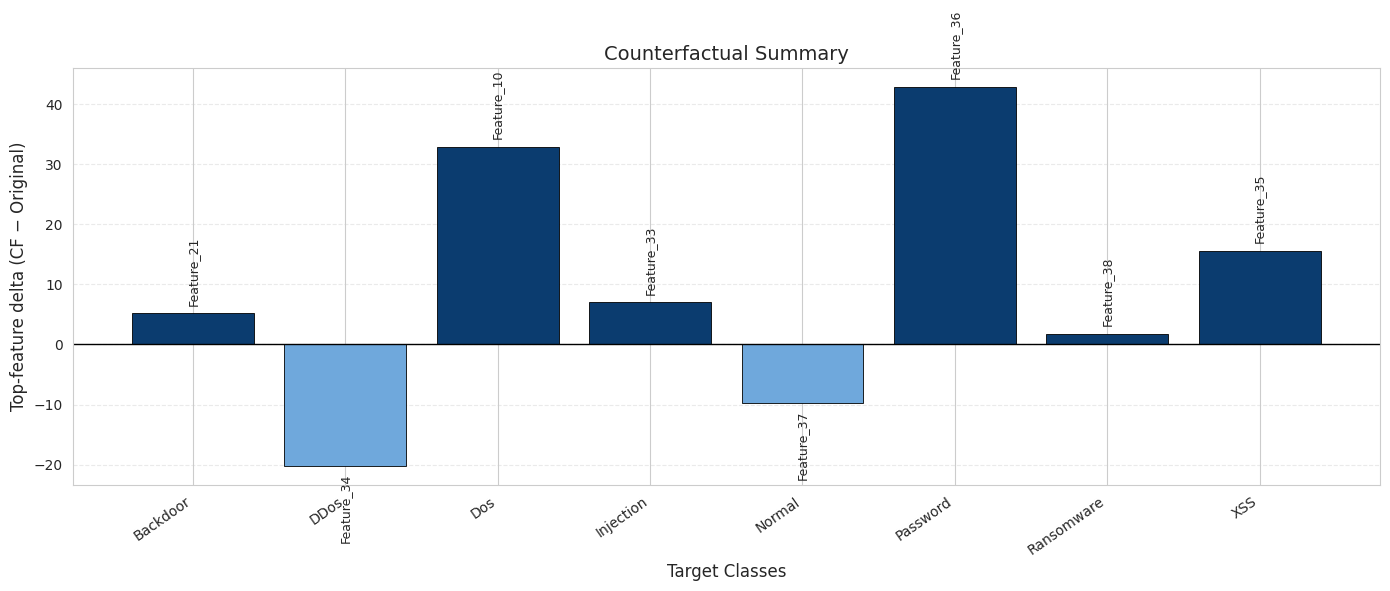

Saved: counterfactual_summary_onegraph_named.png


In [100]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import logging

# ----------------------------
# HIDE WARNINGS (paper notebook)
# ----------------------------
warnings.filterwarnings("ignore")  # hides most warnings
warnings.filterwarnings("ignore", message="Tight layout not applied*")
logging.getLogger("matplotlib").setLevel(logging.ERROR)

# ----------------------------
# results_df should contain:
#   class, feature_idx OR feature, delta
# We will convert idx -> real feature name
# ----------------------------

# If your results already store "feature" as an index like Feature_10, convert it
def resolve_feature_name(feat_value, feature_names_real):
    """
    feat_value can be:
      - int index
      - 'Feature_10' string
      - real feature name string
    """
    if feat_value is None:
        return "NA"

    # case 1: already an integer index
    if isinstance(feat_value, (int, np.integer)):
        i = int(feat_value)
        if 0 <= i < len(feature_names_real):
            return feature_names_real[i]
        return f"Feature_{i}"

    feat_str = str(feat_value)

    # case 2: string like Feature_10
    if feat_str.lower().startswith("feature_"):
        try:
            i = int(feat_str.split("_")[1])
            if 0 <= i < len(feature_names_real):
                return feature_names_real[i]
        except:
            pass

    # case 3: already a real name
    return feat_str


# ---- Ensure feature_names_real exists ----
if "feature_names_real" not in globals():
    feature_names_real = [f"Feature_{i}" for i in range(X_train_2d.shape[1])]
feature_names_real = feature_names_real[:X_train_2d.shape[1]]

# ---- Convert feature column to real names ----
# res_df must exist from your counterfactual loop
# Expected columns: ["class","feature","delta"] OR ["class","top_feature_idx","delta"]
if "top_feature_idx" in res_df.columns and "feature" not in res_df.columns:
    res_df["feature"] = res_df["top_feature_idx"]

res_df["feature_name"] = res_df["feature"].apply(lambda f: resolve_feature_name(f, feature_names_real))

# ----------------------------
# PLOT (Blue scheme)
# ----------------------------
plt.figure(figsize=(14, 6))

x = np.arange(len(res_df))
vals = res_df["delta"].values.astype(float)

# blue scheme: dark blue for positive, light blue for negative, gray for no-cf/error
colors = []
for feat, v in zip(res_df["feature"].values, vals):
    if str(feat) in ["NO_CF", "NO_CHANGE", "ERROR"]:
        colors.append("#B0B0B0")  # gray
    else:
        colors.append("#0B3C6F" if v >= 0 else "#6FA8DC")  # dark vs light blue

bars = plt.bar(x, vals, color=colors, edgecolor="black", linewidth=0.6)

plt.title("Counterfactual Summary", fontsize=14)
plt.ylabel("Top-feature delta (CF − Original)", fontsize=12)
plt.xlabel("Target Classes", fontsize=12)
plt.xticks(x, res_df["class"].values, rotation=35, ha="right")
plt.axhline(0, color="black", linewidth=1.0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

# feature label on top of each bar (real names)
max_abs = np.nanmax(np.abs(vals)) if np.any(np.isfinite(vals)) else 1.0
offset = 0.03 * max_abs

def shorten(text, n=22):
    text = str(text)
    return text if len(text) <= n else text[:n-3] + "..."

for rect, fname, v in zip(bars, res_df["feature_name"].values, vals):
    if not np.isfinite(v):
        continue

    y = v + offset if v >= 0 else v - offset
    va = "bottom" if v >= 0 else "top"
    plt.text(
        rect.get_x() + rect.get_width() / 2,
        y,
        shorten(fname),
        ha="center",
        va=va,
        rotation=90,
        fontsize=9
    )

plt.tight_layout()
plt.savefig("counterfactual_summary_onegraph_named.png", dpi=600, bbox_inches="tight")
plt.show()

print("Saved: counterfactual_summary_onegraph_named.png")


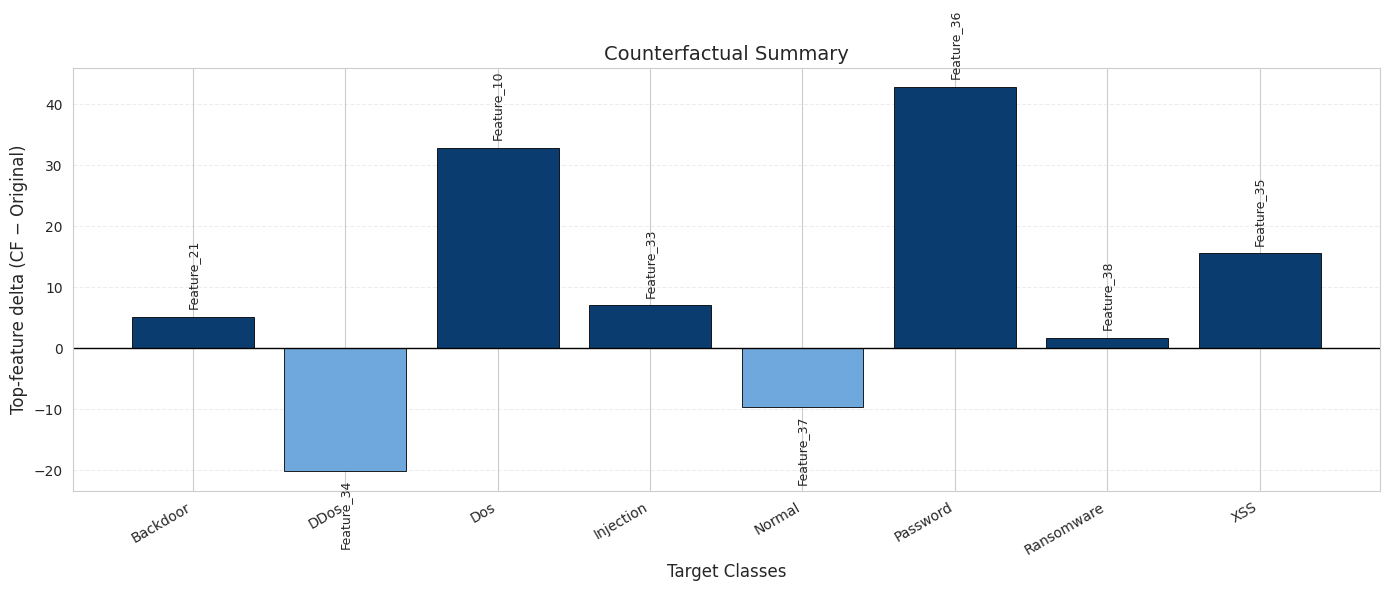

Saved: counterfactual_summary_with_feature_names.png


In [101]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
import logging

# =========================
# HIDE WARNINGS
# =========================
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message="Tight layout not applied*")
logging.getLogger("matplotlib").setLevel(logging.ERROR)

# =========================
# GET REAL FEATURE NAMES
# Priority:
# 1) X_raw.columns (best, pre-scaling)
# 2) df columns after dropping known non-features
# 3) fallback Feature_0..Feature_{F-1}
# =========================
def get_feature_names_real():
    # best case: you still have X_raw from your load_and_process
    if "X_raw" in globals() and hasattr(X_raw, "columns"):
        return list(X_raw.columns)

    # second: you still have df in memory
    if "df" in globals() and hasattr(df, "columns"):
        drop_cols = [c for c in ["src_ip", "dst_ip", "label", "category", "type"] if c in df.columns]
        return [c for c in df.columns if c not in drop_cols]

    # fallback
    if "X_train_2d" in globals():
        return [f"Feature_{i}" for i in range(X_train_2d.shape[1])]

    return []

feature_names_real = get_feature_names_real()

# If you have X_train_2d, align lengths to avoid mismatch
if "X_train_2d" in globals():
    F = X_train_2d.shape[1]
    feature_names_real = feature_names_real[:F]
    if len(feature_names_real) < F:
        feature_names_real += [f"Feature_{i}" for i in range(len(feature_names_real), F)]

# =========================
# RESOLVE FEATURE INDEX -> REAL NAME
# res_df may store:
#  - feature idx as int
#  - "Feature_10" string
#  - real feature name string
# =========================
def resolve_feature_name(feat_value):
    if feat_value is None:
        return "NA"

    # integer index
    if isinstance(feat_value, (int, np.integer)):
        i = int(feat_value)
        if 0 <= i < len(feature_names_real):
            return feature_names_real[i]
        return f"Feature_{i}"

    s = str(feat_value)

    # "Feature_10" style
    if s.lower().startswith("feature_"):
        try:
            i = int(s.split("_")[1])
            if 0 <= i < len(feature_names_real):
                return feature_names_real[i]
        except:
            pass

    # already a real feature name
    return s

# If your df stores "top_feature_idx" instead of "feature"
if "top_feature_idx" in res_df.columns and "feature" not in res_df.columns:
    res_df["feature"] = res_df["top_feature_idx"]

res_df["feature_name"] = res_df["feature"].apply(resolve_feature_name)

# =========================
# PLOT (Blue scheme) + feature name on each bar
# =========================
plt.figure(figsize=(14, 6))

x = np.arange(len(res_df))
vals = res_df["delta"].values.astype(float)

# Colors: dark blue for positive, light blue for negative, gray for failures
colors = []
for feat, v in zip(res_df["feature"].values, vals):
    if str(feat) in ["NO_CF", "NO_CHANGE", "ERROR"]:
        colors.append("#B0B0B0")  # gray
    else:
        colors.append("#0B3C6F" if v >= 0 else "#6FA8DC")  # dark vs light blue

bars = plt.bar(x, vals, color=colors, edgecolor="black", linewidth=0.6)

plt.title("Counterfactual Summary", fontsize=14)
plt.ylabel("Top-feature delta (CF − Original)", fontsize=12)
plt.xlabel("Target Classes", fontsize=12)
plt.xticks(x, res_df["class"].values, rotation=30, ha="right")
plt.axhline(0, color="black", linewidth=1)
plt.grid(axis="y", linestyle="--", alpha=0.35)

# Put feature name above each bar
max_abs = np.nanmax(np.abs(vals)) if np.any(np.isfinite(vals)) else 1.0
offset = 0.03 * max_abs

def shorten(text, n=26):
    text = str(text)
    return text if len(text) <= n else text[:n-3] + "..."

for rect, fname, v in zip(bars, res_df["feature_name"].values, vals):
    if not np.isfinite(v):
        continue
    y = v + offset if v >= 0 else v - offset
    va = "bottom" if v >= 0 else "top"
    plt.text(
        rect.get_x() + rect.get_width()/2,
        y,
        shorten(fname),
        ha="center",
        va=va,
        rotation=90,
        fontsize=9
    )

plt.tight_layout()
plt.savefig("counterfactual_summary_with_feature_names.png", dpi=600, bbox_inches="tight")
plt.show()

print("Saved: counterfactual_summary_with_feature_names.png")


In [34]:
# ============================================================
# UPDATED (PAPER-READY) LIME + SHAP PIPELINE (GPU INFERENCE)
# - Uses REAL X_train / X_test if available (no random data)
# - Fixes feature-name mismatches + dimension mismatches
# - Saves high DPI figures for paper
# - Robust per-class selection + SHAP decision/waterfall
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular

# -------------------------
# CONFIG
# -------------------------
CONFIG = {
    "model_path": "/kaggle/working/gtrs_final_model.pth",
    "input_shape": (44, 1),
    "num_classes": 8
}

# SEEN_CLASSES must match your model output order (label encoder order)
# Example:
# SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Mirai_UDPPlain', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk']

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------
# FEATURE NAMES (robust)
# -------------------------
# Prefer your real columns list if you have it (columns / feature_names_real).
# Fallback: Feature_0..Feature_{F-1}
if "columns" in globals() and columns is not None:
    FEATURE_NAMES = list(columns)
elif "feature_names_real" in globals() and feature_names_real is not None:
    FEATURE_NAMES = list(feature_names_real)
else:
    FEATURE_NAMES = [f"Feature_{i}" for i in range(CONFIG["input_shape"][0])]

# -------------------------
# LOAD MODEL
# -------------------------
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG["input_shape"][0], num_classes=CONFIG["num_classes"]).to(device)
try:
    model.load_state_dict(torch.load(CONFIG["model_path"], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights (not suitable for paper).")
model.eval()

# -------------------------
# USE REAL DATA (IMPORTANT FOR PAPER)
# -------------------------
# If you already have X_train / X_test_final from your pipeline, use them.
# Expected shapes: (N, F, 1). We'll convert to 2D (N, F) for SHAP/LIME.
if "X_train" not in globals() or "X_test_final" not in globals():
    raise NameError("X_train and X_test_final are not defined. Use your dataset pipeline first.")

X_train_3d = X_train
X_test_3d  = X_test_final

X_train_2d = X_train_3d.reshape(X_train_3d.shape[0], X_train_3d.shape[1]).astype(np.float32)
X_test_2d  = X_test_3d.reshape(X_test_3d.shape[0],  X_test_3d.shape[1]).astype(np.float32)

# Ensure consistent feature count across everything (prevents SHAP IndexError)
F = min(X_train_2d.shape[1], X_test_2d.shape[1], CONFIG["input_shape"][0])
X_train_2d = X_train_2d[:, :F]
X_test_2d  = X_test_2d[:, :F]
FEATURE_NAMES = FEATURE_NAMES[:F] if len(FEATURE_NAMES) >= F else FEATURE_NAMES + [f"Feature_{i}" for i in range(len(FEATURE_NAMES), F)]

print(f"Using feature count F={F}, train_2d={X_train_2d.shape}, test_2d={X_test_2d.shape}")

# -------------------------
# GPU PREDICT FUNCTION (SHAP + LIME)
# -------------------------
def predict_proba_gpu(data_2d: np.ndarray) -> np.ndarray:
    """
    data_2d: (N, F)
    returns: (N, C) probabilities
    """
    data_2d = np.asarray(data_2d, dtype=np.float32)
    data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)  # (N,F,1)
    x = torch.from_numpy(data_3d).to(device)
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
    return probs

# -------------------------
# PICK BACKGROUND + TEST SUBSET (speed control)
# -------------------------
# KernelExplainer is slow: keep background small.
background_size = 100
explain_size = 200

background_data_np = shap.sample(X_train_2d, background_size, random_state=42)
test_data_np = X_test_2d[:explain_size]

# Compute predictions for representative samples per class
test_probs = predict_proba_gpu(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

# ============================================================
# 1) LIME (Per-Class) — Feature contribution + Probability plot
# ============================================================
print("\n--- Initializing LIME Explainer ---")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=background_data_np,
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    mode="classification",
    discretize_continuous=True
)

print("\nGenerating Per-Class LIME Explanations...")
for class_idx, class_name in enumerate(SEEN_CLASSES):
    sample_indices = np.where(test_preds == class_idx)[0]
    if len(sample_indices) == 0:
        print(f"Skipping '{class_name}' - no predicted samples in subset.")
        continue

    sample_idx = int(sample_indices[0])
    print(f"--> LIME for {class_name} (sample {sample_idx})")

    exp = lime_explainer.explain_instance(
        data_row=test_data_np[sample_idx],
        predict_fn=predict_proba_gpu,
        num_features=10,
        top_labels=1
    )

    # (A) HTML (optional but good)
    exp.save_to_file(f"lime_explanation_{class_name}.html")

    # (B) Feature contribution plot
    fig = exp.as_pyplot_figure(label=class_idx)
    plt.title(f"LIME Feature Contributions: {class_name}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"lime_feature_plot_{class_name}.png", dpi=600)
    plt.close()

    # (C) Probability plot
    sample_probs = test_probs[sample_idx]
    plt.figure(figsize=(6, 4))
    y_pos = np.arange(len(SEEN_CLASSES))
    plt.barh(y_pos, sample_probs)
    plt.yticks(y_pos, SEEN_CLASSES)
    plt.xlabel("Probability")
    plt.title(f"LIME Probabilities: {class_name} (sample {sample_idx})", fontsize=12)
    plt.xlim(0, 1.05)
    for i, v in enumerate(sample_probs):
        plt.text(v + 0.01, i, f"{v:.2f}", va="center")
    plt.tight_layout()
    plt.savefig(f"lime_probability_plot_{class_name}.png", dpi=600)
    plt.close()

print("LIME charts saved.")

# ============================================================
# 2) SHAP (KernelExplainer) — Summary + Per-class decision/waterfall
# ============================================================
print("\n--- Starting SHAP Analysis (KernelExplainer) ---")
explainer = shap.KernelExplainer(predict_proba_gpu, background_data_np)

# nsamples controls runtime & stability
nsamples = 200
shap_values = explainer.shap_values(test_data_np, nsamples=nsamples)

# -------------------------
# (A) SHAP SUMMARY (beeswarm + bar)
# -------------------------
print("Generating SHAP Summary Plots...")

plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_values,
    test_data_np,
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    show=False
)
plt.title("SHAP Summary (Beeswarm)", fontsize=14)
plt.tight_layout()
plt.savefig("shap_summary_beeswarm.png", dpi=600)
plt.close()

plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_values,
    test_data_np,
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    plot_type="bar",
    show=False
)
plt.title("Mean |SHAP| (Global Importance)", fontsize=14)
plt.tight_layout()
plt.savefig("shap_summary_bar.png", dpi=600)
plt.close()

print("Saved: shap_summary_beeswarm.png, shap_summary_bar.png")

# -------------------------
# (B) PER-CLASS: decision plot + waterfall plot
# -------------------------
print("\nGenerating Per-Class SHAP Decision + Waterfall plots...")

def _ensure_1d(a):
    a = np.array(a)
    a = np.squeeze(a)
    return a.reshape(-1)

for class_idx, class_name in enumerate(SEEN_CLASSES):
    sample_indices = np.where(test_preds == class_idx)[0]
    if len(sample_indices) == 0:
        print(f"Skip {class_name}: no predicted samples in subset.")
        continue

    sample_idx = int(sample_indices[0])
    x_row = _ensure_1d(test_data_np[sample_idx])

    # shap row for that class/sample
    sv_row = _ensure_1d(shap_values[class_idx][sample_idx])

    # base value for this class
    base_val = explainer.expected_value[class_idx] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value

    # align lengths (prevents feature_names mismatch errors)
    L = min(len(x_row), len(sv_row), len(FEATURE_NAMES))
    x_row = x_row[:L]
    sv_row = sv_row[:L]
    fn = FEATURE_NAMES[:L]

    # ---- Decision plot (paper-like) ----
    plt.figure(figsize=(9, 5))
    shap.decision_plot(
        base_value=base_val,
        shap_values=sv_row,
        features=x_row,
        feature_names=fn,
        show=False
    )
    plt.title(f"SHAP Decision Plot: {class_name} (sample {sample_idx})", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"shap_decision_plot_{class_name}.png", dpi=600)
    plt.close()

    # ---- Waterfall plot (like your screenshot) ----
    exp = shap.Explanation(
        values=sv_row,
        base_values=base_val,
        data=x_row,
        feature_names=fn
    )
    plt.figure(figsize=(9, 6))
    shap.waterfall_plot(exp, max_display=12, show=False)
    plt.title(f"SHAP Waterfall Plot: {class_name} (sample {sample_idx})", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"shap_waterfall_plot_{class_name}.png", dpi=600)
    plt.close()

print("\nAll Explainable AI charts generated (LIME + SHAP).")


Loading model...
Model loaded successfully.
Using feature count F=41, train_2d=(133000, 41), test_2d=(48500, 41)

--- Initializing LIME Explainer ---

Generating Per-Class LIME Explanations...
--> LIME for Normal (sample 7)
--> LIME for Ransomware (sample 4)
--> LIME for Backdoor (sample 0)
--> LIME for Injection (sample 11)
--> LIME for DDos (sample 1)
--> LIME for Password (sample 3)
--> LIME for Dos (sample 23)
--> LIME for XSS (sample 8)
LIME charts saved.

--- Starting SHAP Analysis (KernelExplainer) ---


  0%|          | 0/200 [00:00<?, ?it/s]

Generating SHAP Summary Plots...


/tmp/ipykernel_369/2471259014.py:180: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy g

Saved: shap_summary_beeswarm.png, shap_summary_bar.png

Generating Per-Class SHAP Decision + Waterfall plots...


/usr/local/lib/python3.12/dist-packages/shap/plots/_decision.py:78: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xlim)
/usr/local/lib/python3.12/dist-packages/shap/plots/_decision.py:78: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xlim)
/usr/local/lib/python3.12/dist-packages/shap/plots/_decision.py:78: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xlim)



All Explainable AI charts generated (LIME + SHAP).


<Figure size 1200x700 with 0 Axes>

In [ ]:
# ============================================================
# ROBUST PAPER-READY XAI FOR YOUR EXACT PIPELINE
# - Explains (A) CNN classifier probabilities
# - Optionally explains (B) Full System: CNN + MinMaxThreeWayGate ("Emerging" vs Known)
# - SHAP: beeswarm + global bar + stacked-by-class global bar
# - LIME: local per class + global aggregated importance + stacked-by-class
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular

# -------------------------
# XAI CONFIG
# -------------------------
XAI = {
    "seed": 42,

    # SHAP
    "background_size": 100,
    "explain_size": 300,
    "kernel_nsamples": 200,     # used only if KernelExplainer fallback
    "try_deep_explainer": True, # attempt DeepExplainer first (fast)

    # LIME
    "lime_num_features": 10,
    "lime_local_per_class": 1,     # 1 sample per class for paper
    "lime_global_samples": 400,
    "lime_global_top_k": 20,

    # Output
    "dpi": 600
}

np.random.seed(XAI["seed"])

# -------------------------
# Helper: flatten (N,F,1) <-> (N,F)
# -------------------------
def to_2d(X3d):
    X3d = np.asarray(X3d)
    return X3d.reshape(X3d.shape[0], X3d.shape[1]).astype(np.float32)

def to_3d(X2d):
    X2d = np.asarray(X2d, dtype=np.float32)
    return X2d.reshape(X2d.shape[0], X2d.shape[1], 1)

# -------------------------
# Feature names (use your real dataframe columns if you have them)
# -------------------------
if "X_raw" in globals() and isinstance(X_raw, pd.DataFrame):
    FEATURE_NAMES = list(X_raw.columns)
else:
    # fallback
    FEATURE_NAMES = [f"Feature_{i}" for i in range(CONFIG["input_shape"][0])]

# match F
F = min(CONFIG["input_shape"][0], X_train.shape[1], X_test_final.shape[1])
FEATURE_NAMES = FEATURE_NAMES[:F] if len(FEATURE_NAMES) >= F else FEATURE_NAMES + [f"Feature_{i}" for i in range(len(FEATURE_NAMES), F)]

# -------------------------
# Build train/test 2D for SHAP+LIME
# -------------------------
X_train_2d = to_2d(X_train)[:, :F]
X_test_2d  = to_2d(X_test_final)[:, :F]

# background + subset
bg_n = min(XAI["background_size"], len(X_train_2d))
ex_n = min(XAI["explain_size"], len(X_test_2d))

background_np = shap.sample(X_train_2d, bg_n, random_state=XAI["seed"])
test_np = X_test_2d[:ex_n]

print(f"[XAI] background={background_np.shape}, explain={test_np.shape}, F={F}")

# ============================================================
# (A) EXPLAIN BASE CNN CLASSIFIER (softmax outputs)
# ============================================================
def predict_proba_cnn(data_2d: np.ndarray) -> np.ndarray:
    data_2d = np.asarray(data_2d, dtype=np.float32)
    x3d = to_3d(data_2d[:, :F])
    x = torch.from_numpy(x3d).to(device)
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
    return probs

# predicted classes for subset (used in per-class local plots)
test_probs = predict_proba_cnn(test_np)
test_preds = np.argmax(test_probs, axis=1)

# -------------------------
# LIME (A1) LOCAL per predicted class
# -------------------------
print("\n[XAI] LIME LOCAL (CNN)...")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=background_np,
    feature_names=FEATURE_NAMES,
    class_names=list(le.classes_),     # IMPORTANT: matches your trained label order
    mode="classification",
    discretize_continuous=True
)

for class_idx, class_name in enumerate(list(le.classes_)):
    idxs = np.where(test_preds == class_idx)[0]
    if len(idxs) == 0:
        print(f"  - skip {class_name} (no predicted sample in subset)")
        continue

    chosen = idxs[:XAI["lime_local_per_class"]]
    for sample_idx in chosen:
        sample_idx = int(sample_idx)
        exp = lime_explainer.explain_instance(
            data_row=test_np[sample_idx],
            predict_fn=predict_proba_cnn,
            num_features=XAI["lime_num_features"],
            top_labels=len(le.classes_)
        )

        exp.save_to_file(f"lime_local_cnn_{class_name}_sample{sample_idx}.html")

        fig = exp.as_pyplot_figure(label=class_idx)
        plt.title(f"LIME (CNN) Local: {class_name} | sample {sample_idx}", fontsize=13)
        plt.tight_layout()
        plt.savefig(f"lime_local_cnn_{class_name}_sample{sample_idx}.png", dpi=XAI["dpi"])
        plt.close()

print("[XAI] LIME local saved.")

# -------------------------
# LIME (A2) GLOBAL summary (aggregate mean|weight|)
# -------------------------
print("\n[XAI] LIME GLOBAL (CNN)...")
total = min(XAI["lime_global_samples"], len(test_np))
picked = np.random.choice(np.arange(len(test_np)), size=total, replace=False)

lime_abs_sum = np.zeros((len(le.classes_), F), dtype=np.float64)
lime_count   = np.zeros((len(le.classes_),), dtype=np.int64)

for i in picked:
    pred_c = int(test_preds[i])
    exp = lime_explainer.explain_instance(
        data_row=test_np[i],
        predict_fn=predict_proba_cnn,
        num_features=min(F, 30),
        top_labels=len(le.classes_)
    )
    for feat_i, w in exp.local_exp.get(pred_c, []):
        if 0 <= feat_i < F:
            lime_abs_sum[pred_c, feat_i] += abs(w)
    lime_count[pred_c] += 1

lime_mean_abs = lime_abs_sum / np.maximum(lime_count[:, None], 1)
lime_global = lime_mean_abs.mean(axis=0)

top_k = min(XAI["lime_global_top_k"], F)
top_idx = np.argsort(lime_global)[::-1][:top_k]
top_names = [FEATURE_NAMES[j] for j in top_idx]
top_vals  = lime_global[top_idx]

plt.figure(figsize=(10, 6))
plt.barh(np.arange(top_k)[::-1], top_vals[::-1])
plt.yticks(np.arange(top_k)[::-1], top_names[::-1])
plt.xlabel("Mean |LIME weight| (global)")
plt.title("LIME Global Feature Importance (CNN)", fontsize=14)
plt.tight_layout()
plt.savefig("lime_global_cnn.png", dpi=XAI["dpi"])
plt.close()

# stacked-by-class global (paper style)
stack = lime_mean_abs[:, top_idx]
plt.figure(figsize=(12, 7))
left = np.zeros(top_k)
for c in range(len(le.classes_)):
    plt.barh(np.arange(top_k), stack[c], left=left, label=le.classes_[c])
    left += stack[c]
plt.yticks(np.arange(top_k), top_names)
plt.xlabel("Sum of mean |LIME weight| across classes")
plt.title("LIME Global Summary (CNN) — Stacked by Class", fontsize=14)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("lime_global_cnn_stacked.png", dpi=XAI["dpi"])
plt.close()

print("[XAI] Saved: lime_global_cnn.png, lime_global_cnn_stacked.png")

# -------------------------
# SHAP (A3) CNN: DeepExplainer first, else KernelExplainer
# -------------------------
print("\n[XAI] SHAP (CNN)...")

shap_values = None
expected_value = None
used = "KernelExplainer"

if XAI["try_deep_explainer"]:
    try:
        bg_t = torch.from_numpy(to_3d(background_np)).to(device)
        xs_t = torch.from_numpy(to_3d(test_np)).to(device)

        # DeepExplainer needs a torch callable. Your model returns logits; SHAP handles it.
        deep_explainer = shap.DeepExplainer(model, bg_t)
        sv_3d = deep_explainer.shap_values(xs_t, check_additivity=False)

        # convert to list(C) of (N,F)
        shap_values = [np.asarray(sv).reshape(sv.shape[0], sv.shape[1]) for sv in sv_3d]
        expected_value = deep_explainer.expected_value
        used = "DeepExplainer"
    except Exception as e:
        print(f"  DeepExplainer failed -> fallback KernelExplainer. Reason: {type(e).__name__}: {e}")

if shap_values is None:
    kernel_explainer = shap.KernelExplainer(predict_proba_cnn, background_np)
    shap_values = kernel_explainer.shap_values(test_np, nsamples=XAI["kernel_nsamples"])
    expected_value = kernel_explainer.expected_value
    used = "KernelExplainer"

print(f"[XAI] Using SHAP {used}")

# (1) Beeswarm
plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_values,
    test_np,
    feature_names=FEATURE_NAMES,
    class_names=list(le.classes_),
    show=False
)
plt.title("SHAP Summary (Beeswarm) — CNN", fontsize=14)
plt.tight_layout()
plt.savefig("shap_beeswarm_cnn.png", dpi=XAI["dpi"])
plt.close()

# (2) Global bar (mean|SHAP|)
mean_abs_per_class = np.stack([np.mean(np.abs(sv), axis=0) for sv in shap_values], axis=0)  # (C,F)
mean_abs_global = mean_abs_per_class.mean(axis=0)

top_k = min(20, F)
top_idx = np.argsort(mean_abs_global)[::-1][:top_k]
top_names = [FEATURE_NAMES[j] for j in top_idx]
top_vals  = mean_abs_global[top_idx]

plt.figure(figsize=(10, 6))
plt.barh(np.arange(top_k)[::-1], top_vals[::-1])
plt.yticks(np.arange(top_k)[::-1], top_names[::-1])
plt.xlabel("Mean |SHAP| (global)")
plt.title("SHAP Global Feature Importance — CNN", fontsize=14)
plt.tight_layout()
plt.savefig("shap_global_bar_cnn.png", dpi=XAI["dpi"])
plt.close()

# (3) Stacked-by-class global summary (like your screenshot)
stack = mean_abs_per_class[:, top_idx]
plt.figure(figsize=(12, 7))
left = np.zeros(top_k)
for c in range(len(le.classes_)):
    plt.barh(np.arange(top_k), stack[c], left=left, label=le.classes_[c])
    left += stack[c]
plt.yticks(np.arange(top_k), top_names)
plt.xlabel("mean(|SHAP value|) (average impact on model output magnitude)")
plt.title("SHAP Summary Plot (Global Explanation) — CNN (Stacked by Class)", fontsize=14)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("shap_stacked_global_cnn.png", dpi=XAI["dpi"])
plt.close()

print("[XAI] Saved: shap_beeswarm_cnn.png, shap_global_bar_cnn.png, shap_stacked_global_cnn.png")

# ============================================================
# (B) OPTIONAL: EXPLAIN YOUR FULL SYSTEM (CNN + GATE)
#     Output is binary: Known(0) vs Emerging(1)
# ============================================================
# This makes your XAI match your *paper decision*.
# If you want this, keep it ON.
EXPLAIN_GATE = True

if EXPLAIN_GATE:
    print("\n[XAI] Explaining FULL SYSTEM (CNN + MinMaxThreeWayGate): Known vs Emerging")

    # Wrapper: returns P(Emerging) and P(Known) as 2-class probabilities
    def predict_proba_gate_binary(data_2d: np.ndarray) -> np.ndarray:
        """
        data_2d -> CNN probs -> gate region -> output 2-class probabilities
        class0=Known, class1=Emerging
        """
        probs = predict_proba_cnn(data_2d)  # (N,C)
        # gate expects numpy probs
        best_class, region, conf = gate.predict_region(probs)

        # hard labels -> convert to "probabilities"
        # You can soften this if you want by using conf / distance, but hard is acceptable.
        out = np.zeros((len(region), 2), dtype=np.float32)
        for i, r in enumerate(region):
            if r == "inside":
                out[i, 0] = 1.0  # Known
            else:
                out[i, 1] = 1.0  # Emerging
        return out

    gate_class_names = ["Known", "Emerging"]

    # LIME for gate
    lime_gate = lime.lime_tabular.LimeTabularExplainer(
        training_data=background_np,
        feature_names=FEATURE_NAMES,
        class_names=gate_class_names,
        mode="classification",
        discretize_continuous=True
    )

    # pick a few samples predicted Emerging and Known
    gate_probs = predict_proba_gate_binary(test_np)
    gate_pred = np.argmax(gate_probs, axis=1)

    for target_class in [0, 1]:
        idxs = np.where(gate_pred == target_class)[0]
        if len(idxs) == 0:
            print(f"  - skip {gate_class_names[target_class]} (none in subset)")
            continue
        sample_idx = int(idxs[0])

        exp = lime_gate.explain_instance(
            data_row=test_np[sample_idx],
            predict_fn=predict_proba_gate_binary,
            num_features=10,
            top_labels=2
        )

        exp.save_to_file(f"lime_gate_{gate_class_names[target_class]}_sample{sample_idx}.html")
        fig = exp.as_pyplot_figure(label=target_class)
        plt.title(f"LIME (FULL SYSTEM) — {gate_class_names[target_class]} | sample {sample_idx}", fontsize=13)
        plt.tight_layout()
        plt.savefig(f"lime_gate_{gate_class_names[target_class]}_sample{sample_idx}.png", dpi=XAI["dpi"])
        plt.close()

    # SHAP for gate (KernelExplainer is safest for this wrapper)
    gate_explainer = shap.KernelExplainer(predict_proba_gate_binary, background_np)
    gate_shap = gate_explainer.shap_values(test_np, nsamples=200)

    plt.figure(figsize=(12, 7))
    shap.summary_plot(
        gate_shap,
        test_np,
        feature_names=FEATURE_NAMES,
        class_names=gate_class_names,
        show=False
    )
    plt.title("SHAP Summary (Beeswarm) — FULL SYSTEM (Known vs Emerging)", fontsize=14)
    plt.tight_layout()
    plt.savefig("shap_beeswarm_gate.png", dpi=XAI["dpi"])
    plt.close()

    plt.figure(figsize=(10, 6))
    shap.summary_plot(
        gate_shap,
        test_np,
        feature_names=FEATURE_NAMES,
        class_names=gate_class_names,
        plot_type="bar",
        show=False
    )
    plt.title("SHAP Global Importance — FULL SYSTEM (Known vs Emerging)", fontsize=14)
    plt.tight_layout()
    plt.savefig("shap_bar_gate.png", dpi=XAI["dpi"])
    plt.close()

    print("[XAI] Saved: shap_beeswarm_gate.png, shap_bar_gate.png")


In [ ]:
# ============================================================
# FULL UPDATED COPY-PASTE XAI (LIME + SHAP) FOR YOUR PIPELINE
# ✅ Works with your CNNTransformerBiLSTM + LabelEncoder + Gate
# ✅ Fixes SHAP shape mismatch errors (robust normalizer)
# ✅ Produces:
#   - LIME local (per class) + probability plots + HTML
#   - LIME global importance + stacked-by-class
#   - SHAP beeswarm + global bar + stacked-by-class (like your screenshot)
#   - OPTIONAL: Gate XAI (Known vs Emerging) via SHAP+LIME wrappers
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import lime
import lime.lime_tabular
import torch

# -------------------------
# CONFIG
# -------------------------
XAI = {
    "seed": 42,

    # SHAP
    "background_size": 100,
    "explain_size": 300,
    "kernel_nsamples": 200,       # used only if KernelExplainer
    "try_deep_explainer": True,   # attempt DeepExplainer first (fast)

    # LIME
    "lime_num_features": 10,
    "lime_local_per_class": 1,      # local examples per class (paper: 1)
    "lime_global_samples": 400,     # total samples used for global LIME
    "lime_global_top_k": 20,        # top features in global plots

    # OUTPUT
    "dpi": 600
}

np.random.seed(XAI["seed"])
torch.manual_seed(XAI["seed"])

# -------------------------
# REQUIRED VARIABLES CHECK
# -------------------------
required = ["model", "device", "X_train", "X_test_final", "le"]
missing = [r for r in required if r not in globals()]
if missing:
    raise NameError(f"Missing required variables before XAI: {missing}")

# -------------------------
# HELPERS: reshape
# -------------------------
def to_2d(X3d):
    X3d = np.asarray(X3d)
    return X3d.reshape(X3d.shape[0], X3d.shape[1]).astype(np.float32)

def to_3d(X2d):
    X2d = np.asarray(X2d, dtype=np.float32)
    return X2d.reshape(X2d.shape[0], X2d.shape[1], 1)

# -------------------------
# FEATURE NAMES
# If you still have X_raw as a dataframe, we'll use its columns
# else fallback Feature_0..Feature_{F-1}
# -------------------------
INPUT_F = int(CONFIG["input_shape"][0]) if "CONFIG" in globals() and "input_shape" in CONFIG else X_train.shape[1]

if "X_raw" in globals() and isinstance(X_raw, pd.DataFrame):
    FEATURE_NAMES = list(X_raw.columns)
else:
    FEATURE_NAMES = [f"Feature_{i}" for i in range(INPUT_F)]

# Match F robustly
F = min(INPUT_F, X_train.shape[1], X_test_final.shape[1])
FEATURE_NAMES = FEATURE_NAMES[:F] if len(FEATURE_NAMES) >= F else FEATURE_NAMES + [f"Feature_{i}" for i in range(len(FEATURE_NAMES), F)]
FEATURE_NAMES = FEATURE_NAMES[:F]

# -------------------------
# Build 2D arrays for XAI
# -------------------------
X_train_2d = to_2d(X_train)[:, :F]
X_test_2d  = to_2d(X_test_final)[:, :F]

bg_n = min(XAI["background_size"], len(X_train_2d))
ex_n = min(XAI["explain_size"], len(X_test_2d))

background_np = shap.sample(X_train_2d, bg_n, random_state=XAI["seed"])
test_np = X_test_2d[:ex_n]

print(f"[XAI] background={background_np.shape}, explain={test_np.shape}, F={F}")
print(f"[XAI] Model classes = {list(le.classes_)}")

# ============================================================
# (A) CNN CLASSIFIER EXPLANATIONS (softmax outputs)
# ============================================================
def predict_proba_cnn(data_2d: np.ndarray) -> np.ndarray:
    data_2d = np.asarray(data_2d, dtype=np.float32)
    x3d = to_3d(data_2d[:, :F])  # (N,F,1)
    x = torch.from_numpy(x3d).to(device)
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).detach().cpu().numpy()
    return probs

# Predictions for subset
test_probs = predict_proba_cnn(test_np)
test_preds = np.argmax(test_probs, axis=1)

# -------------------------
# LIME LOCAL (per class)
# -------------------------
print("\n[XAI] LIME LOCAL (CNN)...")

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=background_np,
    feature_names=FEATURE_NAMES,
    class_names=list(le.classes_),   # IMPORTANT: exact trained order
    mode="classification",
    discretize_continuous=True
)

for class_idx, class_name in enumerate(list(le.classes_)):
    idxs = np.where(test_preds == class_idx)[0]
    if len(idxs) == 0:
        print(f"  - skip {class_name} (no predicted sample in subset)")
        continue

    chosen = idxs[:XAI["lime_local_per_class"]]
    for sample_idx in chosen:
        sample_idx = int(sample_idx)
        print(f"  -> {class_name} sample={sample_idx}")

        exp = lime_explainer.explain_instance(
            data_row=test_np[sample_idx],
            predict_fn=predict_proba_cnn,
            num_features=XAI["lime_num_features"],
            top_labels=len(le.classes_)
        )

        # HTML
        exp.save_to_file(f"lime_local_cnn_{class_name}_sample{sample_idx}.html")

        # Contribution plot
        fig = exp.as_pyplot_figure(label=class_idx)
        plt.title(f"LIME (CNN) Local: {class_name} | sample {sample_idx}", fontsize=13)
        plt.tight_layout()
        plt.savefig(f"lime_local_cnn_{class_name}_sample{sample_idx}.png", dpi=XAI["dpi"])
        plt.close()

        # Probability plot
        sample_probs = test_probs[sample_idx]
        plt.figure(figsize=(6, 4))
        y_pos = np.arange(len(le.classes_))
        plt.barh(y_pos, sample_probs)
        plt.yticks(y_pos, list(le.classes_))
        plt.xlabel("Probability")
        plt.title(f"Prediction Probabilities | sample {sample_idx}", fontsize=12)
        plt.xlim(0, 1.05)
        for i, v in enumerate(sample_probs):
            plt.text(v + 0.01, i, f"{v:.2f}", va="center")
        plt.tight_layout()
        plt.savefig(f"lime_local_probs_cnn_{class_name}_sample{sample_idx}.png", dpi=XAI["dpi"])
        plt.close()

print("[XAI] LIME local saved.")

# -------------------------
# LIME GLOBAL (aggregate mean|weight|)
# -------------------------
print("\n[XAI] LIME GLOBAL (CNN)...")
total = min(XAI["lime_global_samples"], len(test_np))
picked = np.random.choice(np.arange(len(test_np)), size=total, replace=False)

C = len(le.classes_)
lime_abs_sum = np.zeros((C, F), dtype=np.float64)
lime_count   = np.zeros((C,), dtype=np.int64)

for i in picked:
    pred_c = int(test_preds[i])
    exp = lime_explainer.explain_instance(
        data_row=test_np[i],
        predict_fn=predict_proba_cnn,
        num_features=min(F, 30),
        top_labels=C
    )
    for feat_i, w in exp.local_exp.get(pred_c, []):
        if 0 <= feat_i < F:
            lime_abs_sum[pred_c, feat_i] += abs(w)
    lime_count[pred_c] += 1

lime_mean_abs = lime_abs_sum / np.maximum(lime_count[:, None], 1)
lime_global = lime_mean_abs.mean(axis=0)

top_k = min(XAI["lime_global_top_k"], F)
top_idx = np.argsort(lime_global)[::-1][:top_k]
top_names = [FEATURE_NAMES[j] for j in top_idx]
top_vals  = lime_global[top_idx]

plt.figure(figsize=(10, 6))
ypos = np.arange(top_k)
plt.barh(ypos, top_vals[::-1])
plt.yticks(ypos, top_names[::-1])
plt.xlabel("Mean |LIME weight| (global)")
plt.title("LIME Global Feature Importance (CNN)", fontsize=14)
plt.tight_layout()
plt.savefig("lime_global_cnn.png", dpi=XAI["dpi"])
plt.close()

# stacked-by-class
stack = lime_mean_abs[:, top_idx]  # (C,K)
plt.figure(figsize=(12, 7))
left = np.zeros(top_k)
for c in range(C):
    plt.barh(np.arange(top_k), stack[c][::-1], left=left[::-1], label=le.classes_[c])
    left += stack[c]
plt.yticks(np.arange(top_k), top_names[::-1])
plt.xlabel("Sum of mean |LIME weight| across classes")
plt.title("LIME Global Summary (CNN) — Stacked by Class", fontsize=14)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("lime_global_cnn_stacked.png", dpi=XAI["dpi"])
plt.close()

print("[XAI] Saved: lime_global_cnn.png, lime_global_cnn_stacked.png")

# ============================================================
# SHAP (CNN) — robust aggregation that FIXES shape mismatch
# ============================================================
print("\n[XAI] SHAP (CNN)...")

shap_values = None
expected_value = None
used = "KernelExplainer"

if XAI["try_deep_explainer"]:
    try:
        bg_t = torch.from_numpy(to_3d(background_np)).to(device)
        xs_t = torch.from_numpy(to_3d(test_np)).to(device)

        deep_explainer = shap.DeepExplainer(model, bg_t)
        sv = deep_explainer.shap_values(xs_t, check_additivity=False)

        # sv is list(C) of (N,F,1) or (N,F)
        shap_values = [np.asarray(s).reshape(s.shape[0], s.shape[1]) for s in sv]
        expected_value = deep_explainer.expected_value
        used = "DeepExplainer"
    except Exception as e:
        print(f"  DeepExplainer failed -> fallback KernelExplainer. Reason: {type(e).__name__}: {e}")

if shap_values is None:
    kernel_explainer = shap.KernelExplainer(predict_proba_cnn, background_np)
    shap_values = kernel_explainer.shap_values(test_np, nsamples=XAI["kernel_nsamples"])
    expected_value = kernel_explainer.expected_value
    used = "KernelExplainer"

print(f"[XAI] Using SHAP {used}")
print("[XAI] SHAP shapes (first 3 classes):")
for i in range(min(3, len(shap_values))):
    print(i, np.asarray(shap_values[i]).shape)

# -------------------------
# SHAP summary beeswarm
# -------------------------
plt.figure(figsize=(12, 7))
shap.summary_plot(
    shap_values,
    test_np,
    feature_names=FEATURE_NAMES,
    class_names=list(le.classes_),
    show=False
)
plt.title("SHAP Summary (Beeswarm) — CNN", fontsize=14)
plt.tight_layout()
plt.savefig("shap_beeswarm_cnn.png", dpi=XAI["dpi"])
plt.close()

# -------------------------
# Robust SHAP aggregation FIX (prevents your error)
# -------------------------
def shap_to_NF(sv, F_expected):
    """
    Convert class shap array to (N,F). Handles:
    (N,F), (N,F,1), (N,1,F), (F,), (F,1), etc.
    """
    sv = np.asarray(sv)
    sv = np.squeeze(sv)

    if sv.ndim == 1:
        sv = sv.reshape(1, -1)

    # last dim is features
    if sv.shape[-1] == F_expected:
        return sv

    # maybe (F,N)
    if sv.shape[0] == F_expected and sv.shape[-1] != F_expected:
        return sv.T

    # clip safe
    f = min(F_expected, sv.shape[-1])
    return sv[:, :f]

mean_abs_per_class = []
for c in range(C):
    sv_nf = shap_to_NF(shap_values[c], F)
    mean_abs_per_class.append(np.mean(np.abs(sv_nf), axis=0))

mean_abs_per_class = np.stack(mean_abs_per_class, axis=0)  # (C, F_eff)
F_eff = mean_abs_per_class.shape[1]
feature_names_eff = FEATURE_NAMES[:F_eff]

mean_abs_global = mean_abs_per_class.mean(axis=0)

top_k = min(20, F_eff)
top_idx = np.argsort(mean_abs_global)[::-1][:top_k]
top_names = [feature_names_eff[j] for j in top_idx]
top_vals  = mean_abs_global[top_idx]

# -------------------------
# SHAP global bar (FIXED)
# -------------------------
plt.figure(figsize=(10, 6))
ypos = np.arange(top_k)
plt.barh(ypos, top_vals[::-1])
plt.yticks(ypos, top_names[::-1])
plt.xlabel("Mean |SHAP| (global)")
plt.title("SHAP Global Feature Importance — CNN", fontsize=14)
plt.tight_layout()
plt.savefig("shap_global_bar_cnn.png", dpi=XAI["dpi"])
plt.close()

# -------------------------
# SHAP stacked-by-class (like your screenshot) (FIXED)
# -------------------------
stack = mean_abs_per_class[:, top_idx]  # (C, top_k)

plt.figure(figsize=(12, 7))
left = np.zeros(top_k)
for c in range(C):
    plt.barh(np.arange(top_k), stack[c][::-1], left=left[::-1], label=le.classes_[c])
    left += stack[c]

plt.yticks(np.arange(top_k), top_names[::-1])
plt.xlabel("mean(|SHAP value|) (average impact on model output magnitude)")
plt.title("SHAP Summary Plot (Global Explanation) — CNN (Stacked by Class)", fontsize=14)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("shap_stacked_global_cnn.png", dpi=XAI["dpi"])
plt.close()

print("[XAI] Saved: shap_beeswarm_cnn.png, shap_global_bar_cnn.png, shap_stacked_global_cnn.png")

# ============================================================
# OPTIONAL: FULL SYSTEM (CNN + Gate) XAI
# Known(0) vs Emerging(1)
# ============================================================
EXPLAIN_GATE = True

if EXPLAIN_GATE:
    if "gate" not in globals():
        print("\n[XAI] gate not found in globals() -> skipping FULL SYSTEM XAI.")
    else:
        print("\n[XAI] FULL SYSTEM XAI (CNN+Gate): Known vs Emerging")

        def predict_proba_gate_binary(data_2d: np.ndarray) -> np.ndarray:
            cnn_probs = predict_proba_cnn(data_2d)  # (N,C)
            best_class, region, conf = gate.predict_region(cnn_probs)

            out = np.zeros((len(region), 2), dtype=np.float32)  # [Known, Emerging]
            for i, r in enumerate(region):
                if r == "inside":
                    out[i, 0] = 1.0
                else:
                    out[i, 1] = 1.0
            return out

        gate_names = ["Known", "Emerging"]

        # LIME local for gate
        lime_gate = lime.lime_tabular.LimeTabularExplainer(
            training_data=background_np,
            feature_names=FEATURE_NAMES,
            class_names=gate_names,
            mode="classification",
            discretize_continuous=True
        )

        gate_probs = predict_proba_gate_binary(test_np)
        gate_pred = np.argmax(gate_probs, axis=1)

        for target in [0, 1]:
            idxs = np.where(gate_pred == target)[0]
            if len(idxs) == 0:
                print(f"  - skip {gate_names[target]} (none in subset)")
                continue

            sample_idx = int(idxs[0])

            exp = lime_gate.explain_instance(
                data_row=test_np[sample_idx],
                predict_fn=predict_proba_gate_binary,
                num_features=10,
                top_labels=2
            )

            exp.save_to_file(f"lime_gate_{gate_names[target]}_sample{sample_idx}.html")
            fig = exp.as_pyplot_figure(label=target)
            plt.title(f"LIME (FULL SYSTEM) — {gate_names[target]} | sample {sample_idx}", fontsize=13)
            plt.tight_layout()
            plt.savefig(f"lime_gate_{gate_names[target]}_sample{sample_idx}.png", dpi=XAI["dpi"])
            plt.close()

        # SHAP for gate (KernelExplainer safest)
        gate_explainer = shap.KernelExplainer(predict_proba_gate_binary, background_np)
        gate_shap = gate_explainer.shap_values(test_np, nsamples=200)

        plt.figure(figsize=(12, 7))
        shap.summary_plot(
            gate_shap,
            test_np,
            feature_names=FEATURE_NAMES,
            class_names=gate_names,
            show=False
        )
        plt.title("SHAP Summary (Beeswarm) — FULL SYSTEM (Known vs Emerging)", fontsize=14)
        plt.tight_layout()
        plt.savefig("shap_beeswarm_gate.png", dpi=XAI["dpi"])
        plt.close()

        plt.figure(figsize=(10, 6))
        shap.summary_plot(
            gate_shap,
            test_np,
            feature_names=FEATURE_NAMES,
            class_names=gate_names,
            plot_type="bar",
            show=False
        )
        plt.title("SHAP Global Importance — FULL SYSTEM (Known vs Emerging)", fontsize=14)
        plt.tight_layout()
        plt.savefig("shap_bar_gate.png", dpi=XAI["dpi"])
        plt.close()

        print("[XAI] Saved: shap_beeswarm_gate.png, shap_bar_gate.png")

print("\n✅ DONE: All XAI figures generated.")
